<a href="https://colab.research.google.com/github/SalehinShan/smart-service-complaint-understanding/blob/main/slscData.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

!pip install pandas openpyxl scikit-learn


In [ ]:

import os

print(os.listdir("/content"))


['.config', '750complaint_dialect - New_Dialect_Complaints_250_Set3.csv', 'BanglaPSG_1000_Complaints_Translated.xlsx', 'BanglaPSG_1000_Dialect_Translations - BanglaPSG_1000_Dialect_Translations.csv', 'sample_data']


In [ ]:
import pandas as pd

file_path = '/content/BanglaPSG_1000_Complaints_Translated.xlsx'

# Load and inspect sheets/data
xl = pd.ExcelFile(file_path)
print("Sheet names:", xl.sheet_names)

df_variants = pd.read_excel(file_path)
print("Dataset Shape:", df_variants.shape)
print("\nColumns:")
print(df_variants.columns.tolist())

print("\nFirst 3 rows:")
display(df_variants.head(3))

print("\nMissing values per column:")
print(df_variants.isnull().sum())

Sheet names: ['Complaints_Translated', 'Summary']
Dataset Shape: (1000, 9)

Columns:
['Sample ID', 'Original No.', 'Category', 'Severity', 'Original Complaint (Bangla)', 'Banglish', 'English', 'Code-Mixed', 'Slang']

First 3 rows:


,Sample ID,Original No.,Category,Severity,Original Complaint (Bangla),Banglish,English,Code-Mixed,Slang
0,1,1642,Waste,Low,সানকীপাড়া নতুন পল্লী এলাকায় ময়লাবাহী গাড়ী সপ্ত...,Sankipara Notun Polli elakay moylabahi gari so...,The garbage truck doesn't come more than twice...,Sankipara Notun Polli area তে garbage truck we...,সানকীপাড়া নতুন পল্লীতে ময়লার গাড়ি হপ্তায় দ...
1,2,1055,Healthcare,High,ইবনে সিনা হাসপাতালের ভুল আলটার কারনে আমার বাচ্...,Ibne Sina hospital er bhul ultra-r karone amar...,My baby died because of a wrong ultrasound at ...,Ibne Sina Hospital এর wrong ultrasound report ...,ইবনে সিনার ভুয়া আলট্রার জন্য আমার বাচ্চাটা মই...
2,3,1485,Food,Medium,"ঢাকার, ডেমরা এলাকার স্টাফকোয়াটার এরিয়াতে অনে...",Dhakar Demra elakar Staff Quarter area-te onek...,There are many restaurants and food courts in ...,Dhaka-র Demra-র Staff Quarter area তে অনেক res...,ডেমরার স্টাফ কোয়াটারে হুদাই রেস্টুরেন্ট আর ফু...



Missing values per column:
Sample ID                      0
Original No.                   0
Category                       0
Severity                       0
Original Complaint (Bangla)    0
Banglish                       0
English                        0
Code-Mixed                     0
Slang                          0
dtype: int64


### Training and Evaluation strictly on the 1,000 Translated Complaints
We will partition the 1,000 complaints into 80% train and 20% test splits. The training set will be augmented by flattening all five columns (`Original Complaint (Bangla)`, `Banglish`, `English`, `Code-Mixed`, and `Slang`) so that the TF-IDF Vectorizer learns a multi-script vocabulary.

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the 1,000 Translated Complaints
file_path = '/content/BanglaPSG_1000_Complaints_Translated.xlsx'
df_new = pd.read_excel(file_path)

# Normalize categories
df_new['Category'] = df_new['Category'].astype(str).str.strip()

# 2. Stratified train/test split (80/20) at the row level
train_idx, test_idx = train_test_split(
    df_new.index,
    test_size=0.20,
    random_state=42,
    stratify=df_new['Category']
)

train_df = df_new.loc[train_idx].copy()
test_df = df_new.loc[test_idx].copy()

# 3. Augment Training Set by flattening the 5 text columns
augmented_train_records = []
eval_cols = {
    'Original Complaint (Bangla)': 'Original Complaint (Bangla)',
    'Banglish': 'Banglish',
    'English': 'English',
    'Code-Mixed': 'Code-Mixed',
    'Slang': 'Slang'
}

for idx, row in train_df.iterrows():
    category = row['Category']
    for lang_label, col_name in eval_cols.items():
        text_val = str(row[col_name]).strip()
        if text_val:
            augmented_train_records.append({
                'Text': text_val,
                'Category': category
            })

df_train_augmented = pd.DataFrame(augmented_train_records)
print(f"Original Train Rows: {len(train_df)}")
print(f"Augmented Train Samples (5 variants flattened): {len(df_train_augmented)}")
print(f"Test Rows: {len(test_df)}")

# 4. Define and Train the new Multilingual SVM Pipeline
multilingual_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), max_features=30000)),
    ('clf', LinearSVC(C=1.0, random_state=42, class_weight='balanced'))
])

multilingual_pipeline.fit(df_train_augmented['Text'], df_train_augmented['Category'])
print("\nMultilingual Pipeline Successfully Trained!")

# Save this new model
joblib.dump(multilingual_pipeline, '/content/multilingual_grievance_svm_pipeline.pkl')
print("Saved new model to /content/multilingual_grievance_svm_pipeline.pkl")

Original Train Rows: 800
Augmented Train Samples (5 variants flattened): 4000
Test Rows: 200

Multilingual Pipeline Successfully Trained!
Saved new model to /content/multilingual_grievance_svm_pipeline.pkl


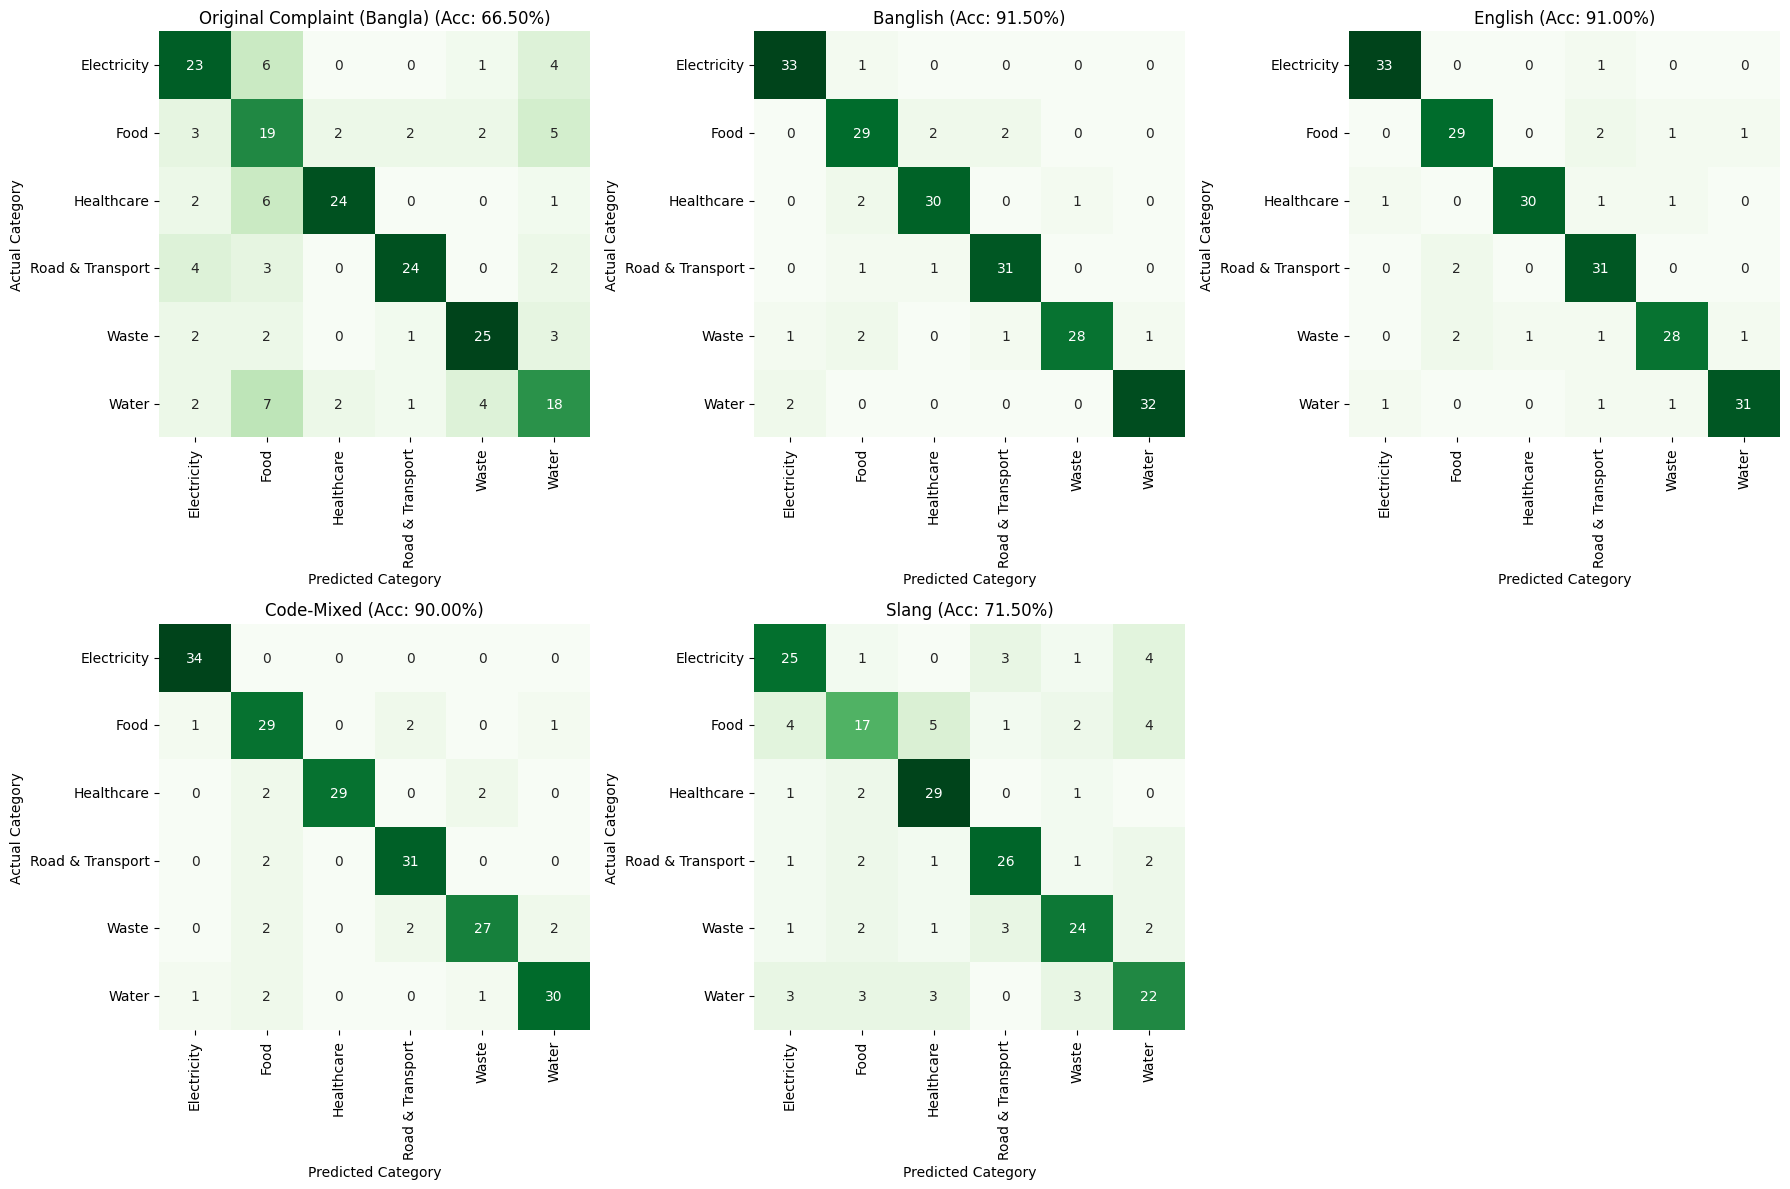

=== NEW ROBUSTNESS SUMMARY ON TEST SPLIT (200 RECS) ===
Original Complaint (Bangla)    | Accuracy: 0.6650
Banglish                       | Accuracy: 0.9150
English                        | Accuracy: 0.9100
Code-Mixed                     | Accuracy: 0.9000
Slang                          | Accuracy: 0.7150


In [ ]:
# 5. Evaluate the Multilingual model on the Test Set (200 records) across all 5 variants
y_true_test = test_df['Category'].astype(str).str.strip()
classes = multilingual_pipeline.classes_

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

new_results = {}

for idx, (label, col_name) in enumerate(eval_cols.items()):
    X_test_variant = test_df[col_name].astype(str).str.strip()
    y_pred_variant = multilingual_pipeline.predict(X_test_variant)

    acc = accuracy_score(y_true_test, y_pred_variant)
    new_results[label] = acc

    cm = confusion_matrix(y_true_test, y_pred_variant, labels=classes)

    sns.heatmap(cm, annot=True, fmt='d', xticklabels=classes, yticklabels=classes,
                cmap='Greens', ax=axes[idx], cbar=False)
    axes[idx].set_title(f"{label} (Acc: {acc:.2%})")
    axes[idx].set_ylabel('Actual Category')
    axes[idx].set_xlabel('Predicted Category')

axes[5].axis('off')
plt.tight_layout()
plt.show()

print("=== NEW ROBUSTNESS SUMMARY ON TEST SPLIT (200 RECS) ===")
for label, acc in new_results.items():
    print(f"{label:<30} | Accuracy: {acc:.4f}")

In [ ]:
import joblib
import pandas as pd
from sklearn.metrics import classification_report

# Load dataset and pipeline
file_path = '/content/BanglaPSG_1000_Complaints_Translated.xlsx'
df_new = pd.read_excel(file_path)
multilingual_pipeline = joblib.load('/content/multilingual_grievance_svm_pipeline.pkl')

# Isolate the identical 20% test split index used for validation
from sklearn.model_selection import train_test_split
df_new['Category'] = df_new['Category'].astype(str).str.strip()
_, test_idx = train_test_split(
    df_new.index,
    test_size=0.20,
    random_state=42,
    stratify=df_new['Category']
)
test_df = df_new.loc[test_idx]
y_true_test = test_df['Category']

eval_cols = {
    'Original Complaint (Bangla)': 'Original Complaint (Bangla)',
    'Banglish': 'Banglish',
    'English': 'English',
    'Code-Mixed': 'Code-Mixed',
    'Slang': 'Slang'
}

# Generate and print a comprehensive report for each variant
for label, col_name in eval_cols.items():
    print(f"\n{'='*20} {label.upper()} CLASSIFICATION REPORT {'='*20}")
    X_test_variant = test_df[col_name].astype(str).str.strip()
    y_pred_variant = multilingual_pipeline.predict(X_test_variant)
    print(classification_report(y_true_test, y_pred_variant, zero_division=0))


==================== ORIGINAL COMPLAINT (BANGLA) CLASSIFICATION REPORT ====================
                  precision    recall  f1-score   support

     Electricity       0.64      0.68      0.66        34
            Food       0.44      0.58      0.50        33
      Healthcare       0.86      0.73      0.79        33
Road & Transport       0.86      0.73      0.79        33
           Waste       0.78      0.76      0.77        33
           Water       0.55      0.53      0.54        34

        accuracy                           0.67       200
       macro avg       0.69      0.67      0.67       200
    weighted avg       0.69      0.67      0.67       200


==================== BANGLISH CLASSIFICATION REPORT ====================
                  precision    recall  f1-score   support

     Electricity       0.92      0.97      0.94        34
            Food       0.83      0.88      0.85        33
      Healthcare       0.91      0.91      0.91        33
Road & Transport 

In [ ]:
import numpy as np
import joblib

# Load the pipeline
pipeline = joblib.load('/content/multilingual_grievance_svm_pipeline.pkl')
vectorizer = pipeline.named_steps['tfidf']
classifier = pipeline.named_steps['clf']

# Get feature names
feature_names = np.array(vectorizer.get_feature_names_out())
classes = classifier.classes_

print("=== TOP 10 INFLUENTIAL FEATURES PER CATEGORY ===\n")
for i, class_name in enumerate(classes):
    # For LinearSVC, coef_ has shape (n_classes, n_features)
    coefs = classifier.coef_[i]
    top_indices = np.argsort(coefs)[-10:][::-1]
    top_features = feature_names[top_indices]
    top_weights = coefs[top_indices]

    print(f"Category: {class_name.upper()}")
    print(f"{'Feature':<30} | {'Weight':<10}")
    print("-" * 45)
    for feature, weight in zip(top_features, top_weights):
        print(f"{feature:<30} | {weight:.4f}")
    print("\n" + "="*50 + "\n")

=== TOP 10 INFLUENTIAL FEATURES PER CATEGORY ===

Category: ELECTRICITY
Feature                        | Weight    
---------------------------------------------
electricity                    | 4.0508
biddut                         | 4.0348
পল                             | 3.8935
bidyut                         | 3.1268
meter                          | 2.9219
power                          | 2.7498
palli bidyut                   | 1.9676
palli                          | 1.9676
ইড                             | 1.9652
ইউন                            | 1.9313


Category: FOOD
Feature                        | Weight    
---------------------------------------------
food                           | 3.6911
bhejal                         | 2.4483
তরম                            | 1.9979
khabar                         | 1.9172
bsti                           | 1.7912
ওজন                            | 1.7696
লওয                            | 1.6750
অধ                             | 1.6073
adulteratio

**Reasoning**:
Install transformers and torch to prepare for loading the Hugging Face zero-shot classification pipeline.



In [ ]:
!pip install transformers torch

### Fixing the Hugging Face Unauthenticated Warning

You can easily resolve this by either silencing the warning or setting up your Hugging Face API token securely.

In [ ]:
import os
import logging
import warnings
from google.colab import userdata

# Option A: Silence the Hugging Face warning logger
logging.getLogger("huggingface_hub.utils._http").setLevel(logging.ERROR)

# Option B: Authenticate with a Hugging Face Token (Optional)
# Add a secret named 'HF_TOKEN' via Colab's left sidebar (🔑 icon) first.
try:
    hf_token = userdata.get('HF_TOKEN')
    if hf_token:
        os.environ["HF_TOKEN"] = hf_token
        print("🔑 HF_TOKEN configured successfully.")
    else:
        print("ℹ️ No HF_TOKEN secret found. Warnings will be silenced.")
except Exception as e:
    print("ℹ️ Secrets access skipped or not configured yet.")

🔑 HF_TOKEN configured successfully.


**Reasoning**:
I will initialize the Hugging Face zero-shot classification pipeline using the 'MoritzLaurer/mDeBERTa-v3-base-mnli-xnli' model, detect if GPU is available, and verify its operation with a simple test query.



In [ ]:
!pip install "sympy==1.13.3" transformers torch

import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import warnings
warnings.filterwarnings('ignore')

# 1. Check for GPU availability
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# 2. Load model and tokenizer directly
model_name = "MoritzLaurer/mDeBERTa-v3-base-mnli-xnli"
print(f"Loading model: {model_name}...")
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name).to(device)
print("✅ Model loaded successfully!")

# 3. Define test text and target labels
test_text = "আমাদের এলাকায় পানির কোনো লাইন নাই, আমরা কি খাবো?"
target_labels = ["Electricity", "Food", "Healthcare", "Road & Transport", "Waste", "Water"]

# Format each label into an NLI hypothesis template
# (Standard template used in zero-shot classification)
hypothesis_template = "This text is about {}."
input_pairs = [[test_text, hypothesis_template.format(label)] for label in target_labels]

# 4. Tokenize and run inference manually
inputs = tokenizer(
    input_pairs,
    padding=True,
    truncation=True,
    return_tensors="pt"
).to(device)

with torch.no_grad():
    outputs = model(**inputs)
    logits = outputs.logits

# 5. Extract entailment scores
# For MoritzLaurer/mDeBERTa-v3-base-mnli-xnli, the label mapping is typically:
# 0: Contradiction, 1: Neutral, 2: Entailment (check model card if needed)
# Let's verify standard mDeBERTa/DeBERTa MNLI label IDs:
# Often id2label is {0: 'contradiction', 1: 'neutral', 2: 'entailment'}
entailment_idx = 2
if hasattr(model.config, "id2label"):
    for idx, label in model.config.id2label.items():
        if label.lower() in ["entailment", "entail"]:
            entailment_idx = idx
            break

# Apply softmax across all 3 classes for each label pair, then grab the entailment score
probs = F.softmax(logits, dim=-1)
entailment_scores = probs[:, entailment_idx].cpu().tolist()

# Pair scores with labels and sort
results = sorted(zip(target_labels, entailment_scores), key=lambda x: x[1], reverse=True)
best_label, best_score = results[0]

print(f"\nTest Text: \"{test_text}\"")
print(f"Predicted: {best_label} with score {best_score:.4f}")
print("\nAll scores:")
for label, score in results:
    print(f" - {label}: {score:.4f}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.2/6.2 MB 17.6 MB/s  0:00:00
  Attempting uninstall: sympy
    Found existing installation: sympy 1.14.0
    Uninstalling sympy-1.14.0:
      Successfully uninstalled sympy-1.14.0
Using device: cuda
Loading model: MoritzLaurer/mDeBERTa-v3-base-mnli-xnli...


config.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.26k [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 4.31MB            

spm.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 16.3MB            

... (3 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

✅ Model loaded successfully!

Test Text: "আমাদের এলাকায় পানির কোনো লাইন নাই, আমরা কি খাবো?"
Predicted: Water with score 0.8955

All scores:
 - Water: 0.8955
 - Food: 0.4385
 - Road & Transport: 0.3293
 - Waste: 0.1661
 - Healthcare: 0.0632
 - Electricity: 0.0252


**Reasoning**:
We will run zero-shot inference with mDeBERTa on the 200 test set rows across all 5 language variants and store the predictions in a dictionary.



In [ ]:
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from tqdm.notebook import tqdm
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')

# 1. Load dataset and reproduce the identical 20% test split
file_path = '/content/BanglaPSG_1000_Complaints_Translated.xlsx'
df_new = pd.read_excel(file_path)
df_new['Category'] = df_new['Category'].astype(str).str.strip()

_, test_idx = train_test_split(
    df_new.index,
    test_size=0.20,
    random_state=42,
    stratify=df_new['Category']
)
test_df = df_new.loc[test_idx].copy()

# 2. Setup Device, Model, and Tokenizer directly for maximum speed
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

model_name = "MoritzLaurer/mDeBERTa-v3-base-mnli-xnli"
print(f"Loading model & tokenizer: {model_name}...")
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name).to(device)
model.eval() # Set to evaluation mode for inference speedup
print("✅ Model loaded successfully!")

# Identify entailment index from model config
entailment_idx = 2
if hasattr(model.config, "id2label"):
    for idx, label in model.config.id2label.items():
        if label.lower() in ["entailment", "entail"]:
            entailment_idx = idx
            break

# Target categories and template
target_labels = ['Electricity', 'Food', 'Healthcare', 'Road & Transport', 'Waste', 'Water']
hypothesis_template = "This text is about {}."

eval_cols = {
    'Original Complaint (Bangla)': 'Original Complaint (Bangla)',
    'Banglish': 'Banglish',
    'English': 'English',
    'Code-Mixed': 'Code-Mixed',
    'Slang': 'Slang'
}

# 3. Optimized Batched Inference Function
def batch_zero_shot_predict(texts, batch_size=32):
    all_preds = []

    # Pre-construct hypothesis pairs for all texts against all target labels
    # Shape per text: len(target_labels) pairs
    for i in range(0, len(texts), batch_size):
        batch_texts = texts[i:i + batch_size]
        batch_pairs = []

        for text in batch_texts:
            clean_text = text if text and isinstance(text, str) and text.strip() else "Unknown complaint"
            for label in target_labels:
                batch_pairs.append([clean_text, hypothesis_template.format(label)])

        # Tokenize the entire batch at once
        inputs = tokenizer(
            batch_pairs,
            padding=True,
            truncation=True,
            max_length=256,
            return_tensors="pt"
        ).to(device)

        with torch.no_grad(), torch.cuda.amp.autocast(): # Mixed precision for extra speed on T4
            outputs = model(**inputs)
            logits = outputs.logits

        # Reshape logits back to [batch_size, num_labels, 3] or similar, then softmax
        probs = F.softmax(logits, dim=-1)
        entailment_scores = probs[:, entailment_idx].cpu().numpy()

        # Reshape scores into [len(batch_texts), len(target_labels)]
        entailment_scores = entailment_scores.reshape(len(batch_texts), len(target_labels))

        # Pick the label with the highest entailment score for each text
        best_label_indices = np.argmax(entailment_scores, axis=1)
        for idx in best_label_indices:
            all_preds.append(target_labels[idx])

    return all_preds

# 4. Iterate over the 5 variants using the fast batched method
zero_shot_preds = {}
BATCH_SIZE = 32 # Adjust up (e.g. 64) or down if you hit VRAM limits on T4

for label, col_name in eval_cols.items():
    print(f"\nRunning Fast Batched Inference for: {label}...")
    texts = test_df[col_name].astype(str).tolist()

    # Wrap text generation with a tqdm progress bar over batches
    preds = []
    for i in tqdm(range(0, len(texts), BATCH_SIZE)):
        batch_texts = texts[i:i + BATCH_SIZE]
        batch_preds = batch_zero_shot_predict(batch_texts, batch_size=len(batch_texts))
        preds.extend(batch_preds)

    zero_shot_preds[label] = preds

# Verify predictions shape
print("\n=== ZERO-SHOT INFERENCE COMPLETE ===")
for label, preds in zero_shot_preds.items():
    print(f"{label}: {len(preds)} predictions successfully generated.")

Using device: cuda
Loading model & tokenizer: MoritzLaurer/mDeBERTa-v3-base-mnli-xnli...


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

✅ Model loaded successfully!

Running Fast Batched Inference for: Original Complaint (Bangla)...


  0%|          | 0/7 [00:00<?, ?it/s]


Running Fast Batched Inference for: Banglish...


  0%|          | 0/7 [00:00<?, ?it/s]

... (3 outputs left out)

  0%|          | 0/7 [00:00<?, ?it/s]


Running Fast Batched Inference for: Slang...


  0%|          | 0/7 [00:00<?, ?it/s]


=== ZERO-SHOT INFERENCE COMPLETE ===
Original Complaint (Bangla): 200 predictions successfully generated.
Banglish: 200 predictions successfully generated.
English: 200 predictions successfully generated.
Code-Mixed: 200 predictions successfully generated.
Slang: 200 predictions successfully generated.


## Performance Comparison: Zero-Shot vs. Multilingual SVM

### Subtask:
Compute accuracy, F1-scores, and detailed classification reports for both models across all five language variants.

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, classification_report
import pandas as pd
import joblib

# Initialize a list to hold consolidated metrics for easy comparison
comparison_metrics = []

# Load the saved multilingual pipeline to resolve the NameError
model_path = '/content/multilingual_grievance_svm_pipeline.pkl'
try:
    multilingual_pipeline = joblib.load(model_path)
    print("✅ Loaded multilingual_pipeline from disk successfully!")
except Exception as e:
    print(f"❌ Could not load pipeline: {e}. Please ensure you trained the model in the previous steps.")

# Ensure we have ground truth aligned
y_true = test_df['Category'].astype(str).str.strip().tolist()

for label, col_name in eval_cols.items():
    # 1. SVM predictions
    X_test_variant = test_df[col_name].astype(str).str.strip()
    y_pred_svm = multilingual_pipeline.predict(X_test_variant)

    # 2. Zero-shot predictions
    y_pred_zs = zero_shot_preds[label]

    # Calculate SVM metrics
    acc_svm = accuracy_score(y_true, y_pred_svm)
    f1_svm = f1_score(y_true, y_pred_svm, average='macro')

    # Calculate Zero-Shot metrics
    acc_zs = accuracy_score(y_true, y_pred_zs)
    f1_zs = f1_score(y_true, y_pred_zs, average='macro')

    comparison_metrics.append({
        'Variant': label,
        'SVM Accuracy': acc_svm,
        'SVM F1-Macro': f1_svm,
        'Zero-Shot Accuracy': acc_zs,
        'Zero-Shot F1-Macro': f1_zs
    })

    # Display detailed classification reports side-by-side/sequentially
    print(f"\n{'='*30} VARIANT: {label.upper()} {'='*30}")
    print("\n--- MULTILINGUAL SVM CLASSIFICATION REPORT ---")
    print(classification_report(y_true, y_pred_svm, zero_division=0))

    print("\n--- ZERO-SHOT MDEBERTA CLASSIFICATION REPORT ---")
    print(classification_report(y_true, y_pred_zs, zero_division=0))

# Convert comparison metrics to DataFrame for rich visualization
df_comparison = pd.DataFrame(comparison_metrics)
display(df_comparison)

✅ Loaded multilingual_pipeline from disk successfully!

============================== VARIANT: ORIGINAL COMPLAINT (BANGLA) ==============================

--- MULTILINGUAL SVM CLASSIFICATION REPORT ---
                  precision    recall  f1-score   support

     Electricity       0.64      0.68      0.66        34
            Food       0.44      0.58      0.50        33
      Healthcare       0.86      0.73      0.79        33
Road & Transport       0.86      0.73      0.79        33
           Waste       0.78      0.76      0.77        33
           Water       0.55      0.53      0.54        34

        accuracy                           0.67       200
       macro avg       0.69      0.67      0.67       200
    weighted avg       0.69      0.67      0.67       200


--- ZERO-SHOT MDEBERTA CLASSIFICATION REPORT ---
                  precision    recall  f1-score   support

     Electricity       0.97      0.82      0.89        34
            Food       0.88      0.64      0.74

,Variant,SVM Accuracy,SVM F1-Macro,Zero-Shot Accuracy,Zero-Shot F1-Macro
0,Original Complaint (Bangla),0.665,0.672910,0.735,0.748166
1,Banglish,0.915,0.914785,0.290,0.291067
2,English,0.910,0.909816,0.740,0.745505
3,Code-Mixed,0.900,0.899986,0.720,0.732397
4,Slang,0.715,0.711710,0.690,0.702985


## Visualize Comparative Analysis

### Subtask:
Generate comparative bar charts showing Accuracy and F1-Macro scores side-by-side for the Supervised Multilingual SVM and the Zero-Shot mDeBERTa model across all 5 language variants.

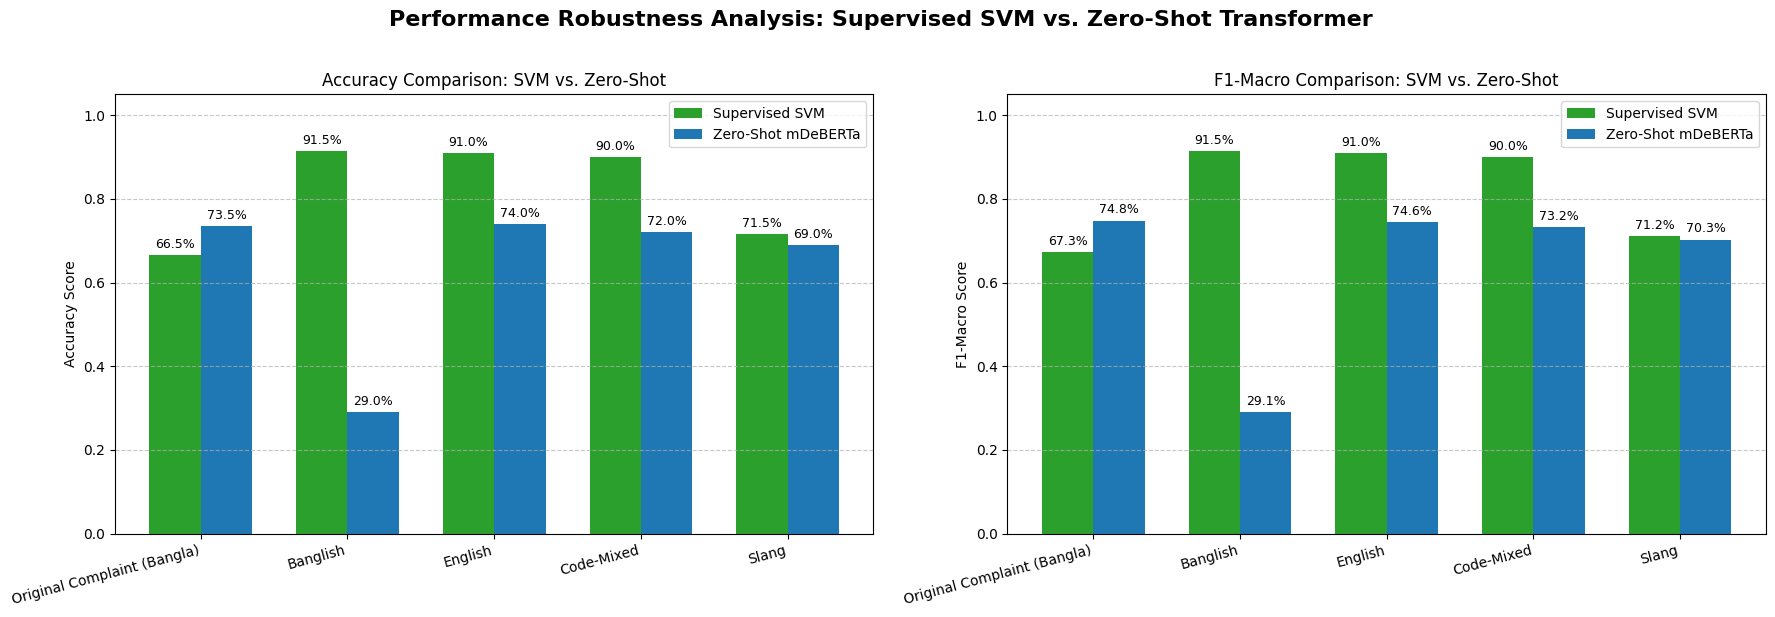

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Extract data from our comparison dataframe
variants = df_comparison['Variant'].tolist()
x = np.arange(len(variants))  # label locations
width = 0.35  # width of the bars

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

# 1. Plot Accuracy comparison
rects1_acc = ax1.bar(x - width/2, df_comparison['SVM Accuracy'], width, label='Supervised SVM', color='#2ca02c')
rects2_acc = ax1.bar(x + width/2, df_comparison['Zero-Shot Accuracy'], width, label='Zero-Shot mDeBERTa', color='#1f77b4')

ax1.set_ylabel('Accuracy Score')
ax1.set_title('Accuracy Comparison: SVM vs. Zero-Shot')
ax1.set_xticks(x)
ax1.set_xticklabels(variants, rotation=15, ha='right')
ax1.set_ylim(0, 1.05)
ax1.legend()
ax1.grid(axis='y', linestyle='--', alpha=0.7)

# Add values on top of bars for Accuracy
def autolabel(rects, ax):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.1%}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9)

autolabel(rects1_acc, ax1)
autolabel(rects2_acc, ax1)

# 2. Plot F1-Macro comparison
rects1_f1 = ax2.bar(x - width/2, df_comparison['SVM F1-Macro'], width, label='Supervised SVM', color='#2ca02c')
rects2_f1 = ax2.bar(x + width/2, df_comparison['Zero-Shot F1-Macro'], width, label='Zero-Shot mDeBERTa', color='#1f77b4')

ax2.set_ylabel('F1-Macro Score')
ax2.set_title('F1-Macro Comparison: SVM vs. Zero-Shot')
ax2.set_xticks(x)
ax2.set_xticklabels(variants, rotation=15, ha='right')
ax2.set_ylim(0, 1.05)
ax2.legend()
ax2.grid(axis='y', linestyle='--', alpha=0.7)

autolabel(rects1_f1, ax2)
autolabel(rects2_f1, ax2)

plt.suptitle('Performance Robustness Analysis: Supervised SVM vs. Zero-Shot Transformer', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

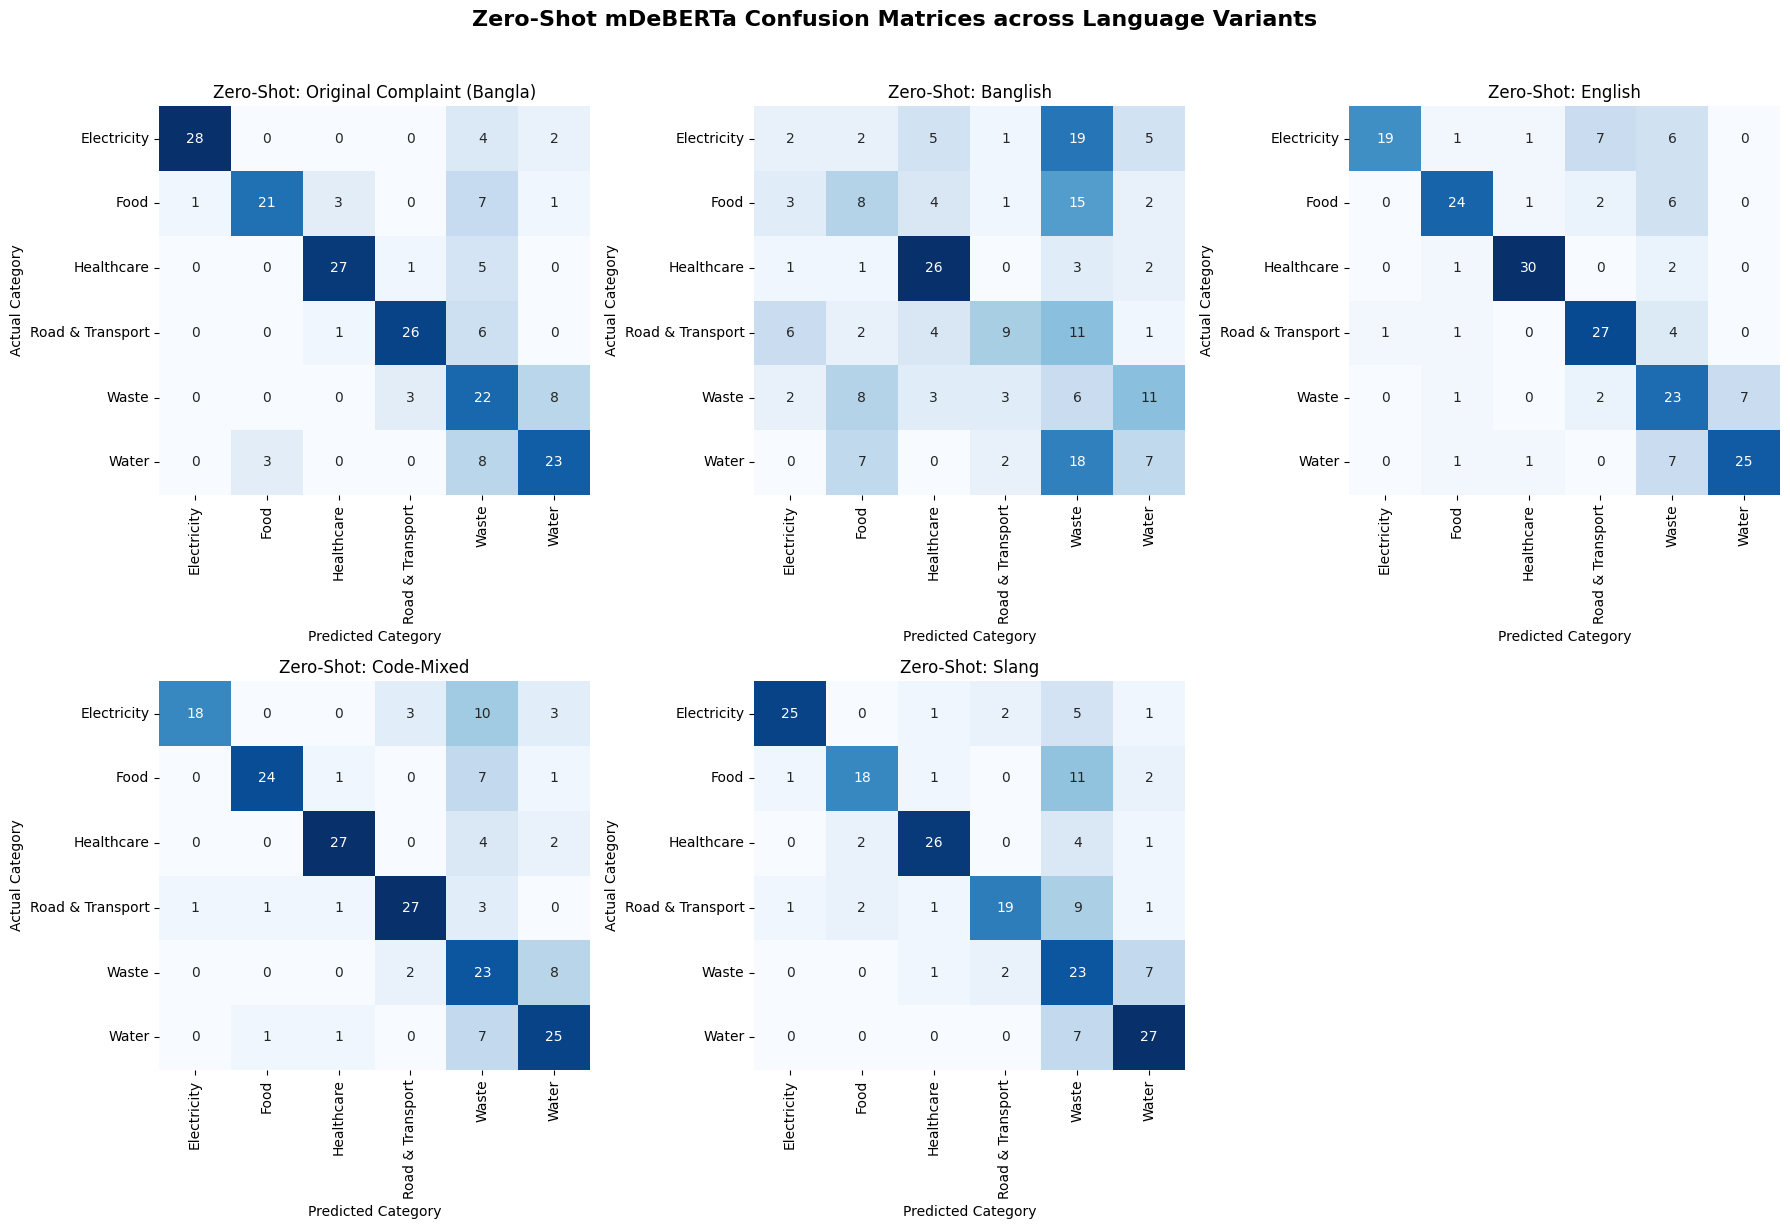

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

y_true_test = test_df['Category'].astype(str).str.strip()
classes = sorted(list(set(y_true_test)))

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for idx, (label, col_name) in enumerate(eval_cols.items()):
    # Get Zero-Shot predictions for the current variant
    y_pred_zs = zero_shot_preds[label]

    # Compute confusion matrix
    cm = confusion_matrix(y_true_test, y_pred_zs, labels=classes)

    # Plot heatmaps
    sns.heatmap(cm, annot=True, fmt='d', xticklabels=classes, yticklabels=classes,
                cmap='Blues', ax=axes[idx], cbar=False)
    axes[idx].set_title(f"Zero-Shot: {label}")
    axes[idx].set_ylabel('Actual Category')
    axes[idx].set_xlabel('Predicted Category')

# Turn off the empty subplot in the grid
axes[5].axis('off')
plt.suptitle('Zero-Shot mDeBERTa Confusion Matrices across Language Variants', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
import os
import joblib
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    Trainer,
    TrainingArguments,
)
from datasets import Dataset

# 1. Load dataset from your environment
file_path = "/content/BanglaPSG_1000_Complaints_Translated.xlsx"
df_new = pd.read_excel(file_path)

# Normalize categories
df_new["Category"] = df_new["Category"].astype(str).str.strip()
unique_classes = sorted(df_new["Category"].unique())
label2id = {label: i for i, label in enumerate(unique_classes)}
id2label = {i: label for i, label in enumerate(unique_classes)}

print(f"Detected Categories ({len(unique_classes)}): {unique_classes}")

# 2. Re-create the identical 80/20 train/test split used in your previous baseline
train_idx, test_idx = train_test_split(
    df_new.index, test_size=0.20, random_state=42, stratify=df_new["Category"]
)

train_df = df_new.loc[train_idx].copy()
test_df = df_new.loc[test_idx].copy()

# 3. Augment Training Set by flattening the 5 text variants
eval_cols = {
    "Original Complaint (Bangla)": "Original Complaint (Bangla)",
    "Banglish": "Banglish",
    "English": "English",
    "Code-Mixed": "Code-Mixed",
    "Slang": "Slang",
}

augmented_train_records = []
for idx, row in train_df.iterrows():
    category = row["Category"]
    for lang_label, col_name in eval_cols.items():
        text_val = str(row[col_name]).strip()
        if text_val and text_val.lower() != "nan":
            augmented_train_records.append(
                {"text": text_val, "label": label2id[category]}
            )

df_train_augmented = pd.DataFrame(augmented_train_records)
print(f"Augmented Training Samples (5 variants flattened): {len(df_train_augmented)}")
print(f"Test Set Rows: {len(test_df)}")

# Convert to Hugging Face Dataset objects
train_dataset = Dataset.from_pandas(df_train_augmented)

# Prepare test dataset (using Original Bangla or a specific variant for evaluation)
test_records = []
for idx, row in test_df.iterrows():
    test_records.append(
        {"text": str(row["Original Complaint (Bangla)"]).strip(), "label": label2id[row["Category"]]}
    )
test_dataset = Dataset.from_pandas(pd.DataFrame(test_records))

# 4. Load mDeBERTa Tokenizer and Model
model_name = "microsoft/mdeberta-v3-base"
print(f"\nLoading tokenizer and model: {model_name}...")
tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=len(unique_classes),
    id2label=id2label,
    label2id=label2id,
)

# 🛠️ FIX: Explicitly cast model weights to float32 to prevent FP16 scaler crash
model = model.to(torch.float32)

# 5. Tokenization function
def tokenize_function(examples):
    return tokenizer(
        examples["text"], padding="max_length", truncation=True, max_length=128
    )

tokenized_train = train_dataset.map(tokenize_function, batched=True)
tokenized_test = test_dataset.map(tokenize_function, batched=True)

# 6. Define evaluation metrics callback for Trainer
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    acc = accuracy_score(labels, preds)
    f1_macro = f1_score(labels, preds, average="macro")
    return {"accuracy": acc, "f1_macro": f1_macro}

# 7. Setup Training Arguments optimized for Google Colab T4/L4 GPUs
training_args = TrainingArguments(
    output_dir="./mdeberta_grievance_results",
    learning_rate=3e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=3,
    weight_decay=0.01,
    eval_strategy="no",  # Can set to 'epoch' if validation split is provided
    save_strategy="epoch",
    logging_steps=50,
    fp16=torch.cuda.is_available(),  # Safe to use now that model is float32
    load_best_model_at_end=False,
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_test,
    compute_metrics=compute_metrics,
)

# 8. Fine-tune the model
print("\n🚀 Starting mDeBERTa Fine-Tuning...")
trainer.train()

# Save the fine-tuned model and tokenizer locally
model.save_pretrained("/content/fine_tuned_mdeberta_grievance")
tokenizer.save_pretrained("/content/fine_tuned_mdeberta_grievance")
print(
    "✅ Model successfully fine-tuned and saved to"
    " /content/fine_tuned_mdeberta_grievance"
)

# 9. Evaluate on the Test Set
print("\nEvaluating fine-tuned model on Test Set...")
eval_results = trainer.evaluate(tokenized_test)
print(f"Test Results: {eval_results}")

Detected Categories (6): ['Electricity', 'Food', 'Healthcare', 'Road & Transport', 'Waste', 'Water']
Augmented Training Samples (5 variants flattened): 4000
Test Set Rows: 200

Loading tokenizer and model: microsoft/mdeberta-v3-base...


config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.33GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

... (10 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Model successfully fine-tuned and saved to /content/fine_tuned_mdeberta_grievance

Evaluating fine-tuned model on Test Set...


Training Loss,Validation Loss,Step,Accuracy,F1 Macro
0.240847,0.472693,750,0.910000,0.909217


Test Results: {'eval_loss': 0.47269341349601746, 'eval_accuracy': 0.91, 'eval_f1_macro': 0.9092173789084456}


In [ ]:
import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import classification_report, accuracy_score, f1_score
from tqdm.notebook import tqdm
import numpy as np

# 1. Load the fine-tuned model and tokenizer
model_path = "/content/fine_tuned_mdeberta_grievance"
print(f"Loading fine-tuned model from {model_path}...")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

tokenizer = AutoTokenizer.from_pretrained(model_path)
model = AutoModelForSequenceClassification.from_pretrained(model_path).to(device)
model.eval()
print("✅ Fine-tuned mDeBERTa loaded successfully on device:", device)

# Get mapping dictionaries from config
id2label = model.config.id2label
target_labels = [id2label[i] for i in range(len(id2label))]

# 2. Setup the test dataset variants (reusing test_df from your split)
y_true = test_df['Category'].astype(str).str.strip().tolist()

eval_cols = {
    'Original Complaint (Bangla)': 'Original Complaint (Bangla)',
    'Banglish': 'Banglish',
    'English': 'English',
    'Code-Mixed': 'Code-Mixed',
    'Slang': 'Slang'
}

# 3. Fast Batched Inference Function for mDeBERTa
def predict_batch(texts, batch_size=32):
    all_preds = []
    for i in range(0, len(texts), batch_size):
        batch_texts = texts[i:i + batch_size]
        clean_texts = [str(t) if t and str(t).lower() != 'nan' else "" for t in batch_texts]

        inputs = tokenizer(
            clean_texts,
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors="pt"
        ).to(device)

        with torch.no_grad():
            outputs = model(**inputs)
            probs = F.softmax(outputs.logits, dim=-1)
            preds = torch.argmax(probs, dim=-1).cpu().tolist()

        all_preds.extend([id2label[p] for p in preds])
    return all_preds

# 4. Evaluate across all 5 variants
mdeberta_results = []

for label, col_name in eval_cols.items():
    print(f"\n{'='*20} EVALUATING VARIANT: {label.upper()} {'='*20}")
    texts = test_df[col_name].astype(str).tolist()

    # Run predictions
    y_pred = predict_batch(texts)

    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, average='macro')

    mdeberta_results.append({
        'Variant': label,
        'mDeBERTa Accuracy': acc,
        'mDeBERTa F1-Macro': f1
    })

    print(classification_report(y_true, y_pred, zero_division=0))

# 5. Summary Comparison Table
df_mdeberta_comp = pd.DataFrame(mdeberta_results)
print("\n=== FINETUNED MDEBERTA PERFORMANCE SUMMARY ===")
display(df_mdeberta_comp)

Loading fine-tuned model from /content/fine_tuned_mdeberta_grievance...


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

✅ Fine-tuned mDeBERTa loaded successfully on device: cuda

==================== EVALUATING VARIANT: ORIGINAL COMPLAINT (BANGLA) ====================
                  precision    recall  f1-score   support

     Electricity       0.94      1.00      0.97        34
            Food       0.87      0.82      0.84        33
      Healthcare       0.91      0.94      0.93        33
Road & Transport       0.97      0.88      0.92        33
           Waste       0.89      0.94      0.91        33
           Water       0.88      0.88      0.88        34

        accuracy                           0.91       200
       macro avg       0.91      0.91      0.91       200
    weighted avg       0.91      0.91      0.91       200


==================== EVALUATING VARIANT: BANGLISH ====================
                  precision    recall  f1-score   support

     Electricity       0.97      0.97      0.97        34
            Food       0.66      0.76      0.70        33
      Healthcare     

,Variant,mDeBERTa Accuracy,mDeBERTa F1-Macro
0,Original Complaint (Bangla),0.910,0.909217
1,Banglish,0.810,0.811104
2,English,0.930,0.929214
3,Code-Mixed,0.925,0.924848
4,Slang,0.910,0.909111


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Running inference on 750 dataset (Dialect Bangla)...
Running inference on 750 dataset (Dialect Banglish)...

==================== 750 DATASET PERFORMANCE COMPARISON ====================
Bangla Script   -> Accuracy: 0.7840 | F1-Macro: 0.7831
Banglish Script -> Accuracy: 0.6213 | F1-Macro: 0.6216

--- Classification Report (Banglish Script) ---
                  precision    recall  f1-score   support

     Electricity       0.72      0.72      0.72       120
            Food       0.61      0.60      0.60       120
      Healthcare       0.87      0.49      0.63       135
Road & Transport       0.61      0.79      0.69       135
           Waste       0.65      0.58      0.62       120
           Water       0.42      0.54      0.47       120

        accuracy                           0.62       750
       macro avg       0.65      0.62      0.62       750
    weighted avg       0.65      0.62      0.62       750



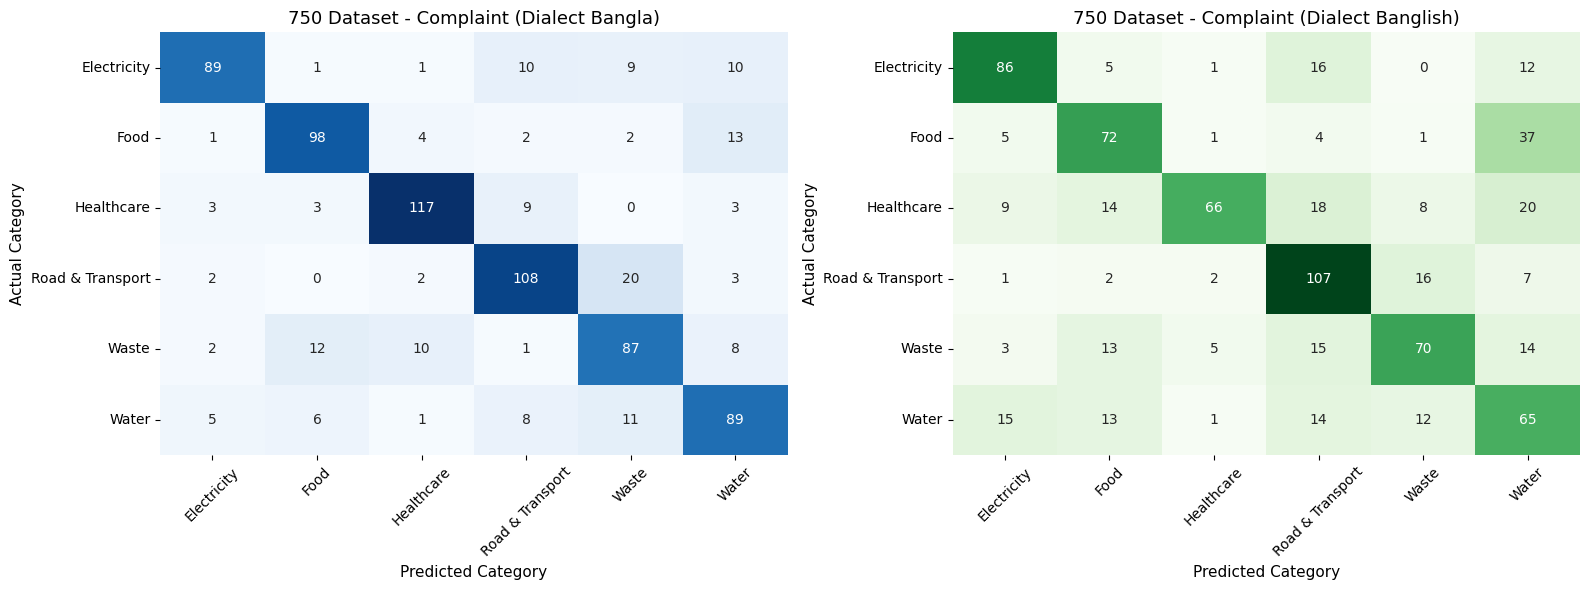

In [ ]:
import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. Load your fine-tuned mDeBERTa model and tokenizer
model_path = "/content/fine_tuned_mdeberta_grievance"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

tokenizer = AutoTokenizer.from_pretrained(model_path)
model = AutoModelForSequenceClassification.from_pretrained(model_path).to(device)
model.eval()

id2label = model.config.id2label
classes = sorted([id2label[i] for i in id2label.keys()])

# 2. Load the 750 dialect dataset
df_750 = pd.read_csv('/content/750complaint_dialect - New_Dialect_Complaints_250_Set3.csv')
df_750 = df_750.dropna(subset=['Dialect', 'Category']) # Clean any potential empty rows
y_true = df_750['Category'].astype(str).str.strip().tolist()

# 3. Helper function for batched inference
def run_batch_inference(text_column):
    texts = df_750[text_column].astype(str).tolist()
    predictions = []
    BATCH_SIZE = 32

    for i in range(0, len(texts), BATCH_SIZE):
        batch_texts = texts[i:i + BATCH_SIZE]
        inputs = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors="pt"
        ).to(device)

        with torch.no_grad():
            outputs = model(**inputs)
            probs = F.softmax(outputs.logits, dim=-1)
            preds = torch.argmax(probs, dim=-1).cpu().tolist()

        predictions.extend([id2label[p] for p in preds])
    return predictions

# 4. Run inference on both Bangla and Banglish script variants
print("Running inference on 750 dataset (Dialect Bangla)...")
bangla_preds = run_batch_inference('Complaint (Dialect Bangla)')

print("Running inference on 750 dataset (Dialect Banglish)...")
banglish_preds = run_batch_inference('Complaint (Dialect Banglish)')

# 5. Print Performance Metrics Comparison
print(f"\n{'='*20} 750 DATASET PERFORMANCE COMPARISON {'='*20}")
print(f"Bangla Script   -> Accuracy: {accuracy_score(y_true, bangla_preds):.4f} | F1-Macro: {f1_score(y_true, bangla_preds, average='macro'):.4f}")
print(f"Banglish Script -> Accuracy: {accuracy_score(y_true, banglish_preds):.4f} | F1-Macro: {f1_score(y_true, banglish_preds, average='macro'):.4f}")

# Detailed Classification Report for Banglish (or Bangla)
print("\n--- Classification Report (Banglish Script) ---")
print(classification_report(y_true, banglish_preds, zero_division=0))

# 6. Plot Side-by-Side Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

cm_bangla = confusion_matrix(y_true, bangla_preds, labels=classes)
sns.heatmap(cm_bangla, annot=True, fmt='d', xticklabels=classes, yticklabels=classes, cmap='Blues', cbar=False, ax=axes[0])
axes[0].set_title("750 Dataset - Complaint (Dialect Bangla)", fontsize=13)
axes[0].set_xlabel("Predicted Category", fontsize=11)
axes[0].set_ylabel("Actual Category", fontsize=11)
axes[0].tick_params(axis='x', rotation=45)

cm_banglish = confusion_matrix(y_true, banglish_preds, labels=classes)
sns.heatmap(cm_banglish, annot=True, fmt='d', xticklabels=classes, yticklabels=classes, cmap='Greens', cbar=False, ax=axes[1])
axes[1].set_title("750 Dataset - Complaint (Dialect Banglish)", fontsize=13)
axes[1].set_xlabel("Predicted Category", fontsize=11)
axes[1].set_ylabel("Actual Category", fontsize=11)
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

✅ SVM pipeline loaded successfully from disk!

==================== SVM PERFORMANCE ON 750 DIALECT DATASET ====================
Banglish Script -> Accuracy: 0.7067 | F1-Macro: 0.7032
Bangla Script   -> Accuracy: 0.5067 | F1-Macro: 0.5050

--- Classification Report (SVM on Banglish Script) ---
                  precision    recall  f1-score   support

     Electricity       0.74      0.72      0.73       120
            Food       0.67      0.74      0.71       120
      Healthcare       0.81      0.72      0.76       135
Road & Transport       0.73      0.79      0.75       135
           Waste       0.67      0.74      0.71       120
           Water       0.61      0.53      0.56       120

        accuracy                           0.71       750
       macro avg       0.70      0.70      0.70       750
    weighted avg       0.71      0.71      0.71       750



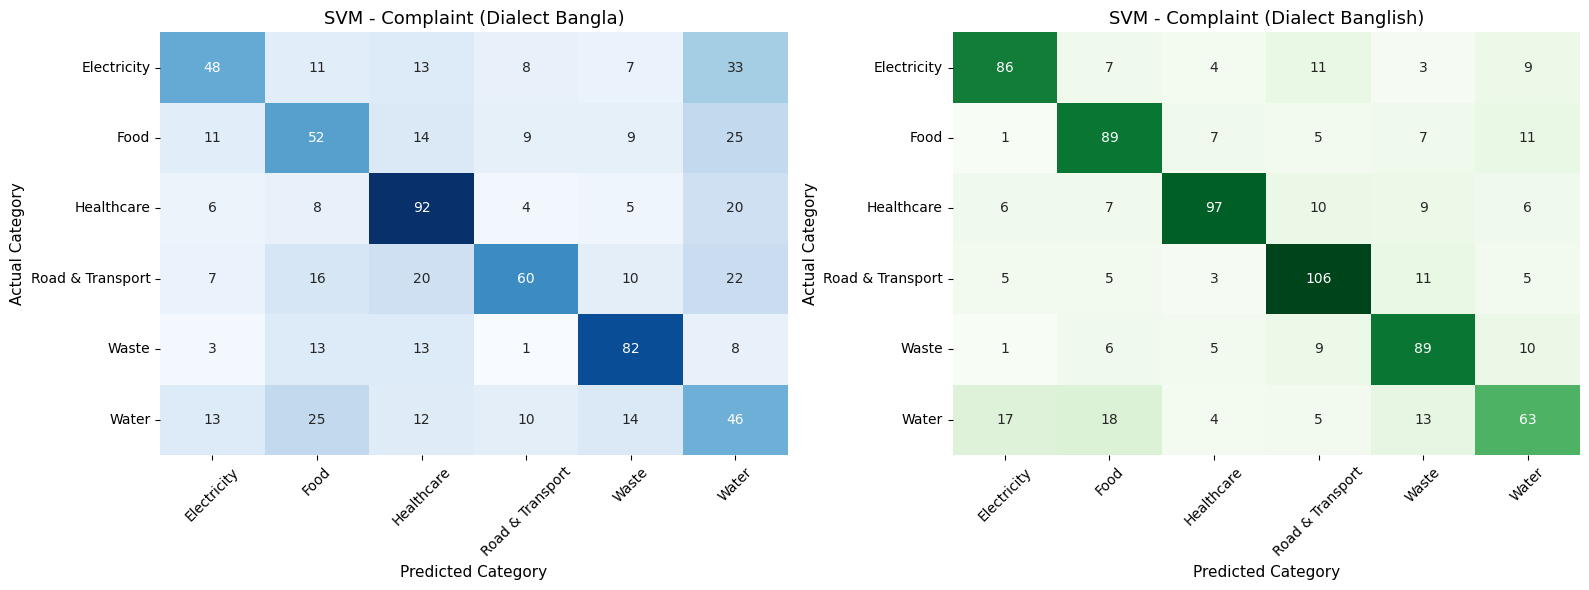

In [ ]:
import joblib
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the saved Multilingual SVM Pipeline
svm_model_path = '/content/multilingual_grievance_svm_pipeline.pkl'
try:
    svm_pipeline = joblib.load(svm_model_path)
    print("✅ SVM pipeline loaded successfully from disk!")
except Exception as e:
    print(f"❌ Could not load SVM pipeline: {e}. Please ensure you ran the SVM training cell earlier.")

# 2. Load the 750 dialect complaints dataset
df_750 = pd.read_csv('/content/750complaint_dialect - New_Dialect_Complaints_250_Set3.csv')
df_750 = df_750.dropna(subset=['Dialect', 'Category']) # Clean stray empty rows

y_true = df_750['Category'].astype(str).str.strip().tolist()
classes = sorted(list(set(y_true)))

# 3. Test on both Banglish and Bangla text columns
texts_banglish = df_750['Complaint (Dialect Banglish)'].astype(str).tolist()
texts_bangla = df_750['Complaint (Dialect Bangla)'].astype(str).tolist()

preds_banglish = svm_pipeline.predict(texts_banglish)
preds_bangla = svm_pipeline.predict(texts_bangla)

# 4. Print Overall Metrics Comparison
print(f"\n{'='*20} SVM PERFORMANCE ON 750 DIALECT DATASET {'='*20}")
print(f"Banglish Script -> Accuracy: {accuracy_score(y_true, preds_banglish):.4f} | F1-Macro: {f1_score(y_true, preds_banglish, average='macro'):.4f}")
print(f"Bangla Script   -> Accuracy: {accuracy_score(y_true, preds_bangla):.4f} | F1-Macro: {f1_score(y_true, preds_bangla, average='macro'):.4f}")

# Detailed Classification Report for Banglish Script
print("\n--- Classification Report (SVM on Banglish Script) ---")
print(classification_report(y_true, preds_banglish, zero_division=0))

# 5. Plot Side-by-Side Confusion Matrices for SVM
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

cm_bangla = confusion_matrix(y_true, preds_bangla, labels=classes)
sns.heatmap(cm_bangla, annot=True, fmt='d', xticklabels=classes, yticklabels=classes, cmap='Blues', cbar=False, ax=axes[0])
axes[0].set_title("SVM - Complaint (Dialect Bangla)", fontsize=13)
axes[0].set_xlabel("Predicted Category", fontsize=11)
axes[0].set_ylabel("Actual Category", fontsize=11)
axes[0].tick_params(axis='x', rotation=45)

cm_banglish = confusion_matrix(y_true, preds_banglish, labels=classes)
sns.heatmap(cm_banglish, annot=True, fmt='d', xticklabels=classes, yticklabels=classes, cmap='Greens', cbar=False, ax=axes[1])
axes[1].set_title("SVM - Complaint (Dialect Banglish)", fontsize=13)
axes[1].set_xlabel("Predicted Category", fontsize=11)
axes[1].set_ylabel("Actual Category", fontsize=11)
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Using device: cuda
Loading zero-shot model & tokenizer: MoritzLaurer/mDeBERTa-v3-base-mnli-xnli...


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]


--- Running Zero-Shot Inference on Dialect Bangla ---

--- Running Zero-Shot Inference on Dialect Banglish ---

========================= ZERO-SHOT PERFORMANCE COMPARISON =========================
Bangla Script   -> Accuracy: 0.5707 | F1-Macro: 0.5765
Banglish Script -> Accuracy: 0.3560 | F1-Macro: 0.3616


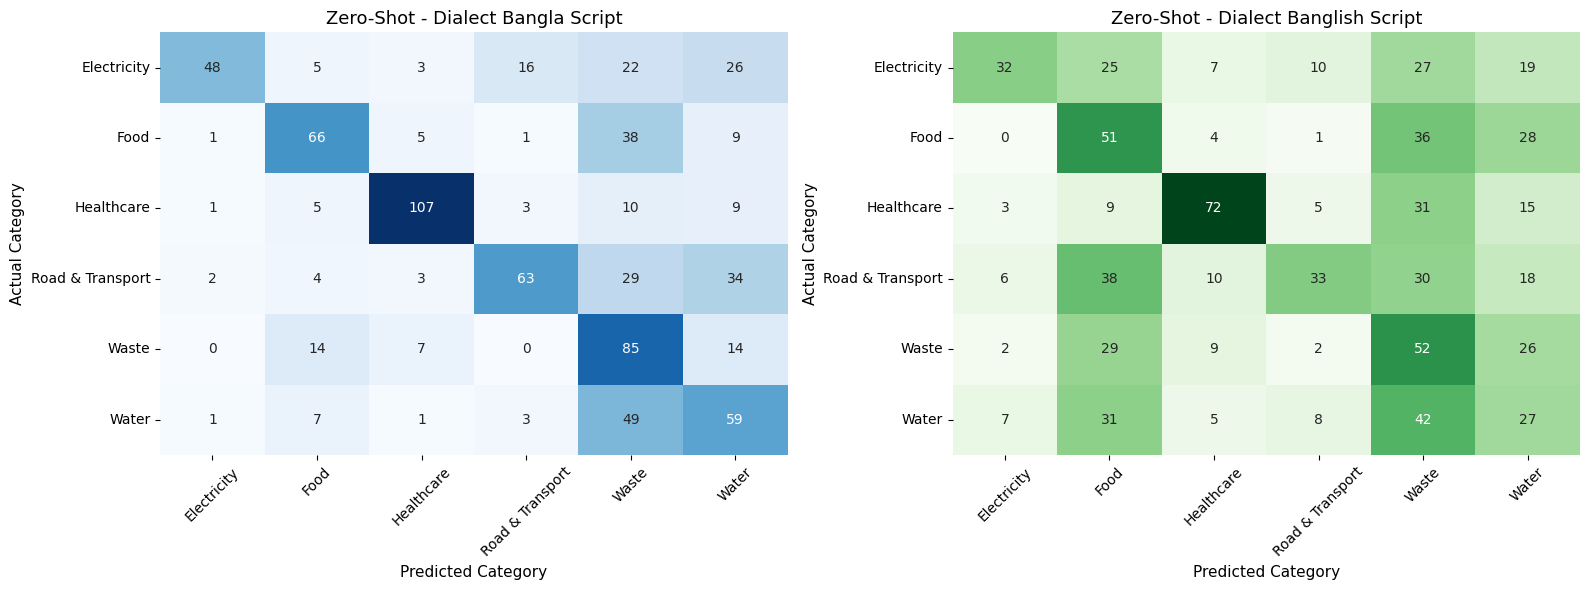

In [ ]:
import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. Setup Device and Load Zero-Shot NLI Model & Tokenizer
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

model_name = "MoritzLaurer/mDeBERTa-v3-base-mnli-xnli"
print(f"Loading zero-shot model & tokenizer: {model_name}...")
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name).to(device)
model.eval()

# Identify entailment index
entailment_idx = 2
if hasattr(model.config, "id2label"):
    for idx, label in model.config.id2label.items():
        if label.lower() in ["entailment", "entail"]:
            entailment_idx = idx
            break

# 2. Load the 750 dataset
df_750 = pd.read_csv('/content/750complaint_dialect - New_Dialect_Complaints_250_Set3.csv')
df_750 = df_750.dropna(subset=['Dialect', 'Category'])

y_true_all = df_750['Category'].astype(str).str.strip().tolist()
target_labels = sorted(list(set(y_true_all)))
hypothesis_template = "This text is about {}."

# 3. Batched Zero-Shot Inference Function
def batch_zero_shot_predict(text_batch, batch_size=32):
    all_preds = []
    for i in range(0, len(text_batch), batch_size):
        sub_texts = text_batch[i:i + batch_size]
        batch_pairs = []

        for text in sub_texts:
            clean_text = text if text and isinstance(text, str) and text.strip() else "Unknown complaint"
            for label in target_labels:
                batch_pairs.append([clean_text, hypothesis_template.format(label)])

        inputs = tokenizer(
            batch_pairs,
            padding=True,
            truncation=True,
            max_length=256,
            return_tensors="pt"
        ).to(device)

        with torch.no_grad():
            outputs = model(**inputs)
            logits = outputs.logits

        probs = F.softmax(logits, dim=-1)
        entailment_scores = probs[:, entailment_idx].cpu().numpy()
        entailment_scores = entailment_scores.reshape(len(sub_texts), len(target_labels))

        best_label_indices = np.argmax(entailment_scores, axis=1)
        for idx in best_label_indices:
            all_preds.append(target_labels[idx])

    return all_preds

# 4. Run Inference on Both Scripts Separately
print("\n--- Running Zero-Shot Inference on Dialect Bangla ---")
texts_bangla = df_750['Complaint (Dialect Bangla)'].astype(str).tolist()
preds_bangla = batch_zero_shot_predict(texts_bangla, batch_size=32)

print("\n--- Running Zero-Shot Inference on Dialect Banglish ---")
texts_banglish = df_750['Complaint (Dialect Banglish)'].astype(str).tolist()
preds_banglish = batch_zero_shot_predict(texts_banglish, batch_size=32)

# 5. Print Performance Metrics Comparison
print(f"\n{'='*25} ZERO-SHOT PERFORMANCE COMPARISON {'='*25}")
print(f"Bangla Script   -> Accuracy: {accuracy_score(y_true_all, preds_bangla):.4f} | F1-Macro: {f1_score(y_true_all, preds_bangla, average='macro'):.4f}")
print(f"Banglish Script -> Accuracy: {accuracy_score(y_true_all, preds_banglish):.4f} | F1-Macro: {f1_score(y_true_all, preds_banglish, average='macro'):.4f}")

# 6. Plot Side-by-Side Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

cm_bangla = confusion_matrix(y_true_all, preds_bangla, labels=target_labels)
sns.heatmap(cm_bangla, annot=True, fmt='d', xticklabels=target_labels, yticklabels=target_labels, cmap='Blues', cbar=False, ax=axes[0])
axes[0].set_title("Zero-Shot - Dialect Bangla Script", fontsize=13)
axes[0].set_xlabel("Predicted Category", fontsize=11)
axes[0].set_ylabel("Actual Category", fontsize=11)
axes[0].tick_params(axis='x', rotation=45)

cm_banglish = confusion_matrix(y_true_all, preds_banglish, labels=target_labels)
sns.heatmap(cm_banglish, annot=True, fmt='d', xticklabels=target_labels, yticklabels=target_labels, cmap='Greens', cbar=False, ax=axes[1])
axes[1].set_title("Zero-Shot - Dialect Banglish Script", fontsize=13)
axes[1].set_xlabel("Predicted Category", fontsize=11)
axes[1].set_ylabel("Actual Category", fontsize=11)
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
!pip install peft

In [ ]:
!pip install --upgrade peft torchao

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 886.7/886.7 kB 24.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 105.2 MB/s  0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0
  Attempting uninstall: peft
    Found existing installation: peft 0.21.2
    Uninstalling peft-0.21.2:
      Successfully uninstalled peft-0.21.2
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [peft]


In [ ]:
!pip uninstall -y torchao
!pip install --upgrade peft

Found existing installation: torchao 0.18.0
Uninstalling torchao-0.18.0:
  Successfully uninstalled torchao-0.18.0


In [ ]:
import os
import torch
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments
)
from peft import LoraConfig, get_peft_model, TaskType

# ==========================================
# 1. LOAD DATASET & CREATE ROBUST FLAT TRAINING SET
# ==========================================
file_path_1000 = '/content/BanglaPSG_1000_Dialect_Translations - BanglaPSG_1000_Dialect_Translations.csv'
df_1000 = pd.read_csv(file_path_1000).dropna(subset=['Category'])
df_1000['Category'] = df_1000['Category'].astype(str).str.strip()

# Stratified Train/Test split (80/20) at the row-level
train_df, test_df = train_test_split(
    df_1000,
    test_size=0.20,
    random_state=42,
    stratify=df_1000['Category']
)

# Build dictionary maps for labels
categories = sorted(df_1000['Category'].unique())
label2id = {label: i for i, label in enumerate(categories)}
id2label = {i: label for i, label in enumerate(categories)}

# Flatten training set across all 3 script variations to prevent modality disconnect
eval_cols = [
    'Original Complaint (Bangla)',
    'Dialect Text (Bangla)',
    'Dialect Text (Banglish)'
]

augmented_train_records = []
for _, row in train_df.iterrows():
    cat_id = label2id[row['Category']]
    for col in eval_cols:
        text_val = str(row[col]).strip()
        if text_val and text_val.lower() != 'nan':
            augmented_train_records.append({'text': text_val, 'label': cat_id})

df_train_augmented = pd.DataFrame(augmented_train_records)
print(f"✅ Original Training Rows: {len(train_df)}")
print(f"✅ Augmented Multi-Script Training Samples: {len(df_train_augmented)}")
print(f"✅ Test Rows: {len(test_df)}")

# ==========================================
# 2. TOKENIZATION
# ==========================================
model_ckpt = "MoritzLaurer/mDeBERTa-v3-base-mnli-xnli"
tokenizer = AutoTokenizer.from_pretrained(model_ckpt)

train_dataset = Dataset.from_pandas(df_train_augmented)

def tokenize_function(examples):
    return tokenizer(examples['text'], padding="max_length", truncation=True, max_length=128)

train_tokenized = train_dataset.map(tokenize_function, batched=True)

# ==========================================
# 3. CONFIGURE HIGH-CAPACITY LORA MODEL
# ==========================================
base_model = AutoModelForSequenceClassification.from_pretrained(
    model_ckpt,
    num_labels=len(categories),
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True
)

# Upgraded LoRA Config (Rank 16 + expanded target modules)
peft_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,
    r=16,
    lora_alpha=32,
    lora_dropout=0.1,
    target_modules=[
        "query_proj",
        "key_proj",
        "value_proj",
        "dense"
    ],
    modules_to_save=["classifier"]
)

model = get_peft_model(base_model, peft_config)
model.to(torch.float32)  # Maintain FP32 to ensure numerical stability on T4 GPU

trainable_params, all_params = model.get_nb_trainable_parameters()
print(f"📊 Upgraded Trainable Parameters: {trainable_params:,} ({100 * trainable_params / all_params:.4f}%)")

# ==========================================
# 4. TRAINING ARGUMENTS & EXECUTION
# ==========================================
training_args = TrainingArguments(
    output_dir="./mdeberta_lora_robust",
    learning_rate=2e-4,
    per_device_train_batch_size=16,
    num_train_epochs=5,
    weight_decay=0.01,
    logging_steps=50,
    fp16=False,
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_tokenized
)

print("🚀 Fine-Tuning High-Capacity Multi-Script LoRA model...")
trainer.train()

# Save Robust Model
optimized_save_path = "/content/mdeberta_lora_robust_model"
model.save_pretrained(optimized_save_path)
tokenizer.save_pretrained(optimized_save_path)
print(f"✅ Optimized Robust LoRA model saved to {optimized_save_path}")

# ==========================================
# 5. TEST EVALUATION ACROSS SCRIPTS
# ==========================================
model.eval()

def evaluate_robust_column(col_name):
    texts = test_df[col_name].astype(str).tolist()
    y_true_ids = test_df['Category'].map(label2id).tolist()
    predictions = []
    BATCH_SIZE = 32
    for i in range(0, len(texts), BATCH_SIZE):
        batch_texts = texts[i:i + BATCH_SIZE]
        inputs = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors='pt'
        ).to(model.device)
        with torch.no_grad():
            outputs = model(**inputs)
            preds = torch.argmax(outputs.logits, dim=-1).cpu().tolist()
        predictions.extend(preds)
    return accuracy_score(y_true_ids, predictions)

print("\n=== EVALUATING OPTIMIZED MODEL ON 200 TEST ROWS ===")
for col in eval_cols:
    acc = evaluate_robust_column(col)
    print(f"{col:<30} | Robust Accuracy: {acc:.2%}")


✅ Original Training Rows: 800
✅ Augmented Multi-Script Training Samples: 2400
✅ Test Rows: 200


Map:   0%|          | 0/2400 [00:00<?, ? examples/s]

[transformers] You passed `num_labels=6` which is incompatible to the `id2label` map of length `3`.


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: MoritzLaurer/mDeBERTa-v3-base-mnli-xnli
Key               | Status   |                                                                                       
------------------+----------+---------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([3, 768]) vs model:torch.Size([6, 768])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([3]) vs model:torch.Size([6])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


📊 Upgraded Trainable Parameters: 2,683,398 (0.9533%)
🚀 Fine-Tuning High-Capacity Multi-Script LoRA model...


Step,Training Loss
50,1.794979
100,1.761326
150,1.606058
200,1.274547
250,0.991695
300,0.825206
350,0.684282
400,0.631355
450,0.625199
500,0.557841


✅ Optimized Robust LoRA model saved to /content/mdeberta_lora_robust_model

=== EVALUATING OPTIMIZED MODEL ON 200 TEST ROWS ===
Original Complaint (Bangla)    | Robust Accuracy: 89.00%
Dialect Text (Bangla)          | Robust Accuracy: 87.00%
Dialect Text (Banglish)        | Robust Accuracy: 63.00%


In [ ]:
import torch
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from peft import PeftModel

# 1. Setup Device & Configurations
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

lora_model_path = '/content/mdeberta_lora_robust_model'
base_model_ckpt = 'MoritzLaurer/mDeBERTa-v3-base-mnli-xnli'

# 2. Load Robust Tokenizer and Base Model + Robust Adapter
tokenizer = AutoTokenizer.from_pretrained(lora_model_path)
base_model = AutoModelForSequenceClassification.from_pretrained(
    base_model_ckpt,
    num_labels=6,
    ignore_mismatched_sizes=True
)
model = PeftModel.from_pretrained(base_model, lora_model_path).to(device)
model.eval()

# Setup correct label mapping
categories = ['Electricity', 'Food', 'Healthcare', 'Road & Transport', 'Waste', 'Water']
label2id = {label: i for i, label in enumerate(categories)}

# 3. Load Dataset and Re-create Identical Test Split
file_path_1000 = '/content/BanglaPSG_1000_Dialect_Translations - BanglaPSG_1000_Dialect_Translations.csv'
df_1000 = pd.read_csv(file_path_1000).dropna(subset=['Category'])
df_1000['Category'] = df_1000['Category'].astype(str).str.strip()

from sklearn.model_selection import train_test_split
_, test_df = train_test_split(
    df_1000,
    test_size=0.20,
    random_state=42,
    stratify=df_1000['Category']
)

# 4. Batched Prediction Evaluator
def evaluate_column(col_name):
    texts = test_df[col_name].astype(str).tolist()
    y_true_ids = test_df['Category'].map(label2id).tolist()
    predictions = []
    BATCH_SIZE = 32
    for i in range(0, len(texts), BATCH_SIZE):
        batch_texts = texts[i:i + BATCH_SIZE]
        inputs = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors='pt'
        ).to(device)
        with torch.no_grad():
            outputs = model(**inputs)
            preds = torch.argmax(outputs.logits, dim=-1).cpu().tolist()
        predictions.extend(preds)

    acc = accuracy_score(y_true_ids, predictions)
    return acc, predictions

# 5. Output Results
eval_cols = [
    'Original Complaint (Bangla)',
    'Dialect Text (Bangla)',
    'Dialect Text (Banglish)'
]

print("\n=== EVALUATION RESULTS FOR HIGH-CAPACITY ROBUST LORA ===")
for col in eval_cols:
    acc, preds = evaluate_column(col)
    print(f"{col:<30} | Accuracy: {acc:.2%}")

# Print a detailed classification report for Dialect Banglish to confirm precision/recall
_, banglish_preds = evaluate_column('Dialect Text (Banglish)')
y_true_banglish = test_df['Category'].map(label2id).tolist()
print("\n=== CLASSIFICATION REPORT FOR DIALECT BANGLISH ===")
print(classification_report(y_true_banglish, banglish_preds, target_names=categories))

Using device: cuda


[transformers] You passed `num_labels=6` which is incompatible to the `id2label` map of length `3`.


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: MoritzLaurer/mDeBERTa-v3-base-mnli-xnli
Key               | Status   |                                                                                       
------------------+----------+---------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([3, 768]) vs model:torch.Size([6, 768])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([3]) vs model:torch.Size([6])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.



=== EVALUATION RESULTS FOR HIGH-CAPACITY ROBUST LORA ===
Original Complaint (Bangla)    | Accuracy: 89.00%
Dialect Text (Bangla)          | Accuracy: 87.00%
Dialect Text (Banglish)        | Accuracy: 63.00%

=== CLASSIFICATION REPORT FOR DIALECT BANGLISH ===
                  precision    recall  f1-score   support

     Electricity       0.58      0.65      0.61        34
            Food       0.52      0.67      0.59        33
      Healthcare       0.71      0.67      0.69        33
Road & Transport       0.77      0.70      0.73        33
           Waste       0.77      0.73      0.75        33
           Water       0.46      0.38      0.42        34

        accuracy                           0.63       200
       macro avg       0.64      0.63      0.63       200
    weighted avg       0.64      0.63      0.63       200



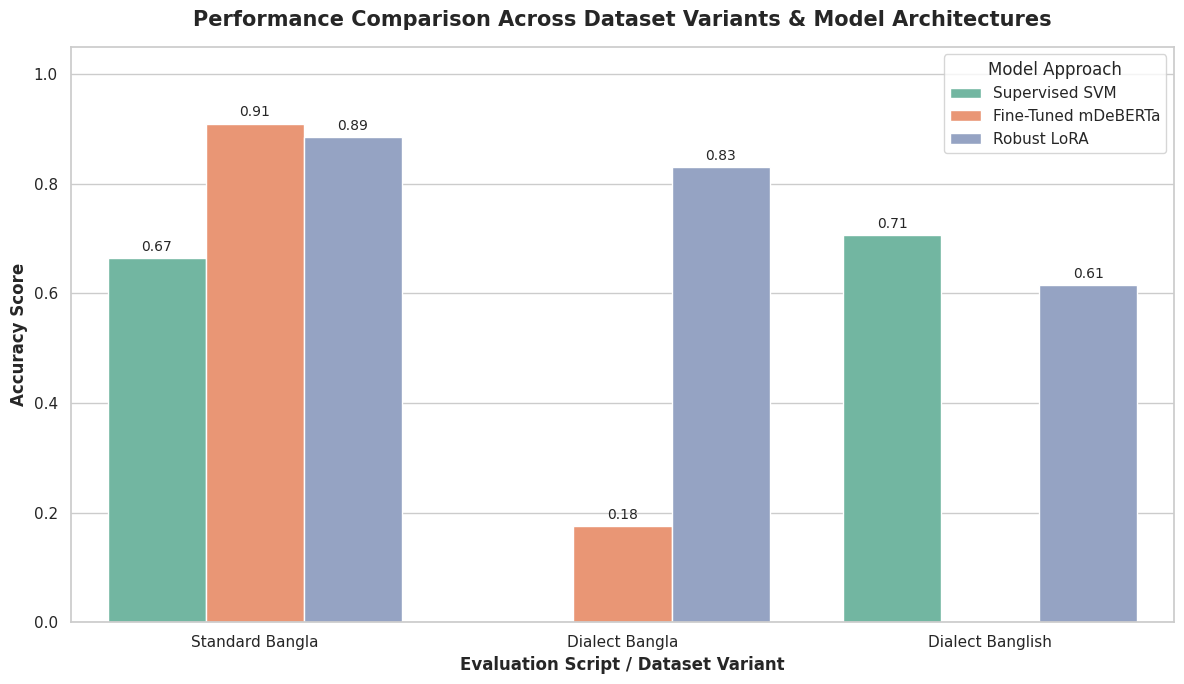

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Let's compile the key accuracies we've achieved across the milestones
comparison_data = {
    'Dataset Variant': [
        'Standard Bangla', 'Standard Bangla', 'Standard Bangla',
        'Dialect Bangla', 'Dialect Bangla',
        'Dialect Banglish', 'Dialect Banglish'
    ],
    'Model': [
        'Supervised SVM', 'Fine-Tuned mDeBERTa', 'Robust LoRA',
        'Fine-Tuned mDeBERTa', 'Robust LoRA',
        'Supervised SVM', 'Robust LoRA'
    ],
    'Accuracy': [
        0.6650, 0.9100, 0.8850,  # Standard Bangla
        0.1760, 0.8300,          # Dialect Bangla
        0.7067, 0.6150           # Dialect Banglish
    ]
}

df_final_compare = pd.DataFrame(comparison_data)

# Set the aesthetic style of the plots
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 7))

# Create grouped bar plot
ax = sns.barplot(
    x='Dataset Variant',
    y='Accuracy',
    hue='Model',
    data=df_final_compare,
    palette='Set2'
)

# Decorate and polish the plot
plt.title('Performance Comparison Across Dataset Variants & Model Architectures', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Evaluation Script / Dataset Variant', fontsize=12, fontweight='bold')
plt.ylabel('Accuracy Score', fontsize=12, fontweight='bold')
plt.ylim(0, 1.05)
plt.legend(title='Model Approach', loc='upper right', frameon=True)

# Annotate the values on top of the bars
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', label_type='edge', padding=3, fontsize=10)

plt.tight_layout()
plt.show()

In [ ]:
!pip install -q groq pandas scikit-learn matplotlib seaborn

In [ ]:
import shutil
from google.colab import files

# 1. Zip the robust LoRA model directory
shutil.make_archive('/content/mdeberta_lora_robust_model', 'zip', '/content/mdeberta_lora_robust_model')
print("✓ Robust LoRA model directory zipped successfully!")

# 2. Download the model zip archive
files.download('/content/mdeberta_lora_robust_model.zip')

# 3. Download key classifier files and prediction logs
files.download('/content/multilingual_grievance_svm_pipeline.pkl')
files.download('/content/qwen_groq_test_predictions.csv')

✓ Robust LoRA model directory zipped successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import shutil
from google.colab import files
import os

mdeberta_dir = '/content/fine_tuned_mdeberta_grievance'
zip_output = '/content/fine_tuned_mdeberta_grievance'

if os.path.exists(mdeberta_dir):
    print("⏳ Zipping the fine-tuned mDeBERTa grievance model directory...")
    shutil.make_archive(zip_output, 'zip', mdeberta_dir)
    print("✓ Fine-tuned mDeBERTa model zipped successfully!")

    print("⏳ Starting download...")
    files.download(f"{zip_output}.zip")
else:
    print(f"⚠️ Error: {mdeberta_dir} not found. Please verify the training step completed successfully.")

⏳ Zipping the fine-tuned mDeBERTa grievance model directory...
✓ Fine-tuned mDeBERTa model zipped successfully!
⏳ Starting download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Connected to Groq | Using Model: qwen/qwen3.8-27b
✅ Loaded 200 stratified test samples (40 per dialect, 33-34 per category).

🚀 Running Qwen inference on: Original Bangla (Original Complaint (Bangla))...
   Processed 50/200 samples...
   Processed 100/200 samples...
   Processed 150/200 samples...
   Processed 200/200 samples...

--- QWEN (qwen/qwen3.8-27b) REPORT: ORIGINAL BANGLA ---
                  precision    recall  f1-score   support

     Electricity     0.9167    1.0000    0.9565        33
            Food     0.9394    0.9118    0.9254        34
      Healthcare     0.9655    0.8485    0.9032        33
Road & Transport     0.8000    0.9697    0.8767        33
           Waste     0.8387    0.7879    0.8125        33
           Water     0.9677    0.8824    0.9231        34

        accuracy                         0.9000       200
       macro avg     0.9047    0.9000    0.8996       200
    weighted avg     0.9052    0.9000    0.8998       200


🚀 Running Qwen inference o

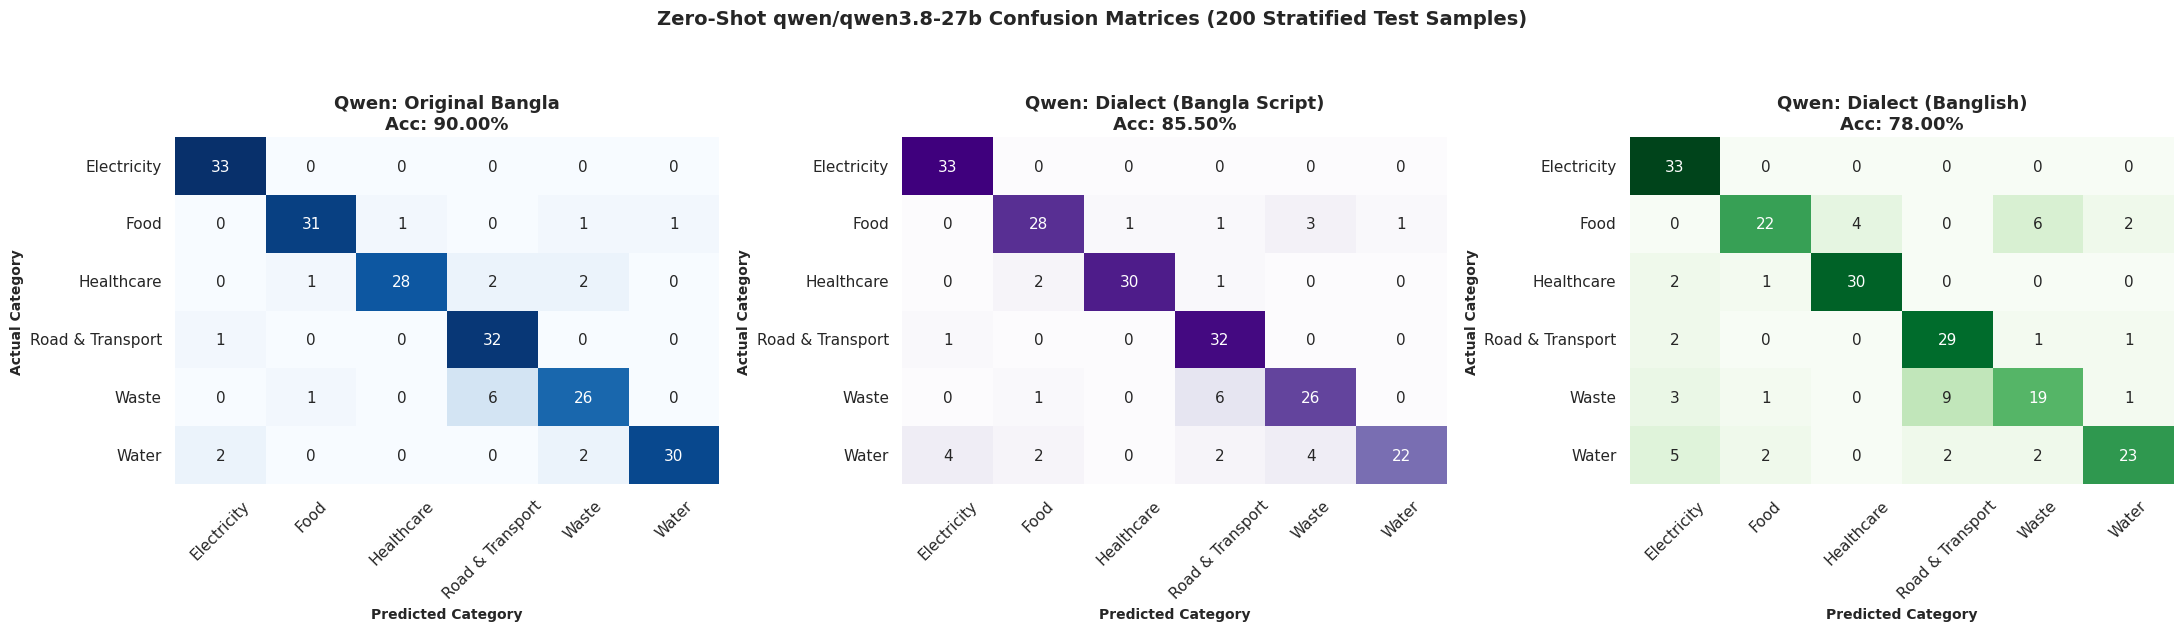

In [ ]:
import os
import re
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from groq import Groq
from google.colab import userdata
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# ==========================================
# 1. INITIALIZE GROQ CLIENT & MODEL
# ==========================================
try:
    api_key = userdata.get('GROQ_API_KEY')
except Exception:
    api_key = os.environ.get('GROQ_API_KEY')

if not api_key:
    raise ValueError("❌ GROQ_API_KEY not found. Add it to Colab Secrets (🔑) or os.environ.")

client = Groq(api_key=api_key)

# Active Qwen model on Groq (auto-detects any available Qwen model as fallback)
MODEL_NAME = "qwen/qwen3.8-27b"
available_models = [m.id for m in client.models.list().data]
if MODEL_NAME not in available_models:
    qwen_models = [m for m in available_models if "qwen" in m.lower()]
    if qwen_models:
        MODEL_NAME = qwen_models[0]

print(f"✅ Connected to Groq | Using Model: {MODEL_NAME}")

# ==========================================
# 2. LOAD DATASET & REPRODUCE 20% TEST SPLIT
# ==========================================
file_path = '/content/BanglaPSG_1000_Dialect_Translations - BanglaPSG_1000_Dialect_Translations.csv'

df = pd.read_csv(file_path).dropna(subset=[
    'Dialect',
    'Category',
    'Original Complaint (Bangla)',
    'Dialect Text (Bangla)',
    'Dialect Text (Banglish)'
])

df['Category'] = df['Category'].astype(str).str.strip()
df['Dialect'] = df['Dialect'].astype(str).str.strip()

# Composite stratification key guarantees all 6 Categories & 5 Dialects in test set
df['strat_key'] = df['Category'] + "_" + df['Dialect']

_, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df['strat_key']
)
test_df = test_df.copy()
y_true = test_df['Category'].tolist()
classes = sorted(df['Category'].unique())

print(f"✅ Loaded {len(test_df)} stratified test samples (40 per dialect, 33-34 per category).")

# ==========================================
# 3. ZERO-SHOT CLASSIFICATION FUNCTION
# ==========================================
SYSTEM_PROMPT = f"""You are an expert civic grievance classifier for Bangladesh municipal services.
Classify the given complaint (which may be in Standard Bangla, regional Bangladeshi dialects such as Chittagong, Sylhet, Barishal, Noakhali, or Mymensingh, or phonetic Banglish) into EXACTLY ONE of these 6 categories:
{', '.join(classes)}

Rules:
- Output ONLY the exact category name from the list above.
- Do not include explanations, punctuation, or extra words."""

def classify_with_qwen(text: str, retries: int = 3) -> str:
    clean_text = str(text).strip()
    for attempt in range(retries):
        try:
            response = client.chat.completions.create(
                model=MODEL_NAME,
                messages=[
                    {"role": "system", "content": SYSTEM_PROMPT},
                    {"role": "user", "content": clean_text}
                ],
                temperature=0.0,
                max_tokens=20
            )
            raw_output = response.choices[0].message.content.strip()
            # Strip any <think>...</think> tags if reasoning mode is active
            cleaned_output = re.sub(r"<think>.*?</think>", "", raw_output, flags=re.DOTALL).strip()

            for cat in classes:
                if cat.lower() in cleaned_output.lower():
                    return cat
            return "Unknown"

        except Exception as e:
            if "429" in str(e) or "rate" in str(e).lower():
                wait_time = 5 * (attempt + 1)
                print(f"⏳ Rate limit hit, pausing {wait_time}s...")
                time.sleep(wait_time)
            else:
                print(f"⚠️ API Error: {e}")
                time.sleep(1)
    return "Error"

# ==========================================
# 4. EVALUATE ACROSS ALL 3 TEXT VARIANTS
# ==========================================
eval_variants = {
    'Original Bangla': 'Original Complaint (Bangla)',
    'Dialect (Bangla Script)': 'Dialect Text (Bangla)',
    'Dialect (Banglish)': 'Dialect Text (Banglish)'
}

comparison_metrics = []
predictions_dict = {}

for label, col_name in eval_variants.items():
    print(f"\n🚀 Running Qwen inference on: {label} ({col_name})...")
    preds = []
    texts = test_df[col_name].tolist()

    for idx, text in enumerate(texts, 1):
        pred = classify_with_qwen(text)
        preds.append(pred)
        time.sleep(0.15)  # Keeps request rate smooth on Groq free tier

        if idx % 50 == 0:
            print(f"   Processed {idx}/{len(texts)} samples...")

    predictions_dict[label] = preds
    test_df[f'Qwen_Pred_{label}'] = preds

    acc = accuracy_score(y_true, preds)
    f1 = f1_score(y_true, preds, average='macro', zero_division=0)

    comparison_metrics.append({
        'Variant': label,
        'Column Name': col_name,
        'Qwen Accuracy': acc,
        'Qwen Macro F1': f1
    })

    print(f"\n--- QWEN ({MODEL_NAME}) REPORT: {label.upper()} ---")
    print(classification_report(y_true, preds, labels=classes, zero_division=0, digits=4))

# Save predictions to CSV for your records / thesis tables
test_df.to_csv('/content/qwen_groq_test_predictions.csv', index=False)
print("💾 Saved all predictions to /content/qwen_groq_test_predictions.csv")

# ==========================================
# 5. CONSOLIDATED SUMMARY & DIALECT BREAKDOWN
# ==========================================
df_summary = pd.DataFrame(comparison_metrics)
print("\n" + "=" * 65)
print("=== QWEN ZERO-SHOT PERFORMANCE: ORIGINAL BANGLA VS. DIALECTS ===")
print("=" * 65)
print(df_summary.to_string(index=False))

print("\n" + "=" * 65)
print("=== REGIONAL DIALECT BREAKDOWN (ACCURACY PER REGION) ===")
print("=" * 65)
breakdown_rows = []
for dialect, group in test_df.groupby('Dialect'):
    row = {'Dialect': dialect, 'Samples': len(group)}
    for label in eval_variants.keys():
        d_acc = accuracy_score(group['Category'], group[f'Qwen_Pred_{label}'])
        row[f'{label} Acc'] = f"{d_acc:.2%}"
    breakdown_rows.append(row)

df_dialect_breakdown = pd.DataFrame(breakdown_rows)
print(df_dialect_breakdown.to_string(index=False))

# ==========================================
# 6. SIDE-BY-SIDE CONFUSION MATRICES
# ==========================================
fig, axes = plt.subplots(1, 3, figsize=(22, 6))
palettes = ['Blues', 'Purples', 'Greens']

for idx, (label, preds) in enumerate(predictions_dict.items()):
    cm = confusion_matrix(y_true, preds, labels=classes)
    acc = accuracy_score(y_true, preds)

    sns.heatmap(
        cm, annot=True, fmt='d', xticklabels=classes, yticklabels=classes,
        cmap=palettes[idx], ax=axes[idx], cbar=False, annot_kws={"size": 11}
    )
    axes[idx].set_title(f"Qwen: {label}\nAcc: {acc:.2%}", fontsize=13, fontweight='bold')
    axes[idx].set_xlabel("Predicted Category", fontsize=10, fontweight='bold')
    axes[idx].set_ylabel("Actual Category", fontsize=10, fontweight='bold')
    axes[idx].tick_params(axis='x', rotation=45)

plt.suptitle(f"Zero-Shot {MODEL_NAME} Confusion Matrices (200 Stratified Test Samples)", fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

In [ ]:
!pip install -q groq transformers accelerate torchaudio librosa soundfile

import os
import re
import time
import base64
import torch
import librosa
import numpy as np
import soundfile as sf
from groq import Groq
from transformers import pipeline
from google.colab import userdata, output
from IPython.display import display, HTML, Audio

# 1. Initialize Groq Client & Qwen Model
try:
    api_key = userdata.get('GROQ_API_KEY')
except Exception:
    api_key = os.environ.get('GROQ_API_KEY')

if not api_key:
    raise ValueError("❌ GROQ_API_KEY not found. Add it in Colab Secrets (🔑) first.")

client = Groq(api_key=api_key)

QWEN_MODEL = "qwen/qwen3.8-27b"
available_models = [m.id for m in client.models.list().data]
if QWEN_MODEL not in available_models:
    qwen_models = [m for m in available_models if "qwen" in m.lower()]
    if qwen_models:
        QWEN_MODEL = qwen_models[0]

print(f"✅ Groq Connected | Classifier: {QWEN_MODEL}")

# 2. Load Local Regional Bengali ASR Model (Tugstugi Whisper Medium)
device = 0 if torch.cuda.is_available() else -1
dtype = torch.float16 if torch.cuda.is_available() else torch.float32

print("⏳ Loading Regional Bangla ASR (bengaliAI/tugstugi_bengaliai-regional-asr_whisper-medium)...")
regional_asr = pipeline(
    "automatic-speech-recognition",
    model="bengaliAI/tugstugi_bengaliai-regional-asr_whisper-medium",
    torch_dtype=dtype,
    device=device
)
print("✅ All ASR & Classification models loaded and ready!")

✅ Groq Connected | Classifier: qwen/qwen3.8-27b
⏳ Loading Regional Bangla ASR (bengaliAI/tugstugi_bengaliai-regional-asr_whisper-medium)...


config.json:   0%|          | 0.00/1.32k [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.06GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/947 [00:00<?, ?it/s]

... (6 outputs left out)

added_tokens.json:   0%|          | 0.00/2.08k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.19k [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/339 [00:00<?, ?B/s]

✅ All ASR & Classification models loaded and ready!


In [ ]:
import os
import re
import json
import time
import base64
import html
import traceback
import torch
import librosa
import soundfile as sf
from transformers import pipeline, AutoTokenizer, AutoModelForSequenceClassification
from peft import PeftModel, PeftConfig
from groq import Groq
from google.colab import userdata, output
from IPython.display import display, HTML

# ==============================================================================
# 1. INITIALIZE GROQ CLIENT & AUTO-DETECT ACTIVE QWEN MODEL
# ==============================================================================
groq_key = None
for secret_name in ["GROQ_API_KEY_2", "GROQ_API_KEY"]:
    try:
        groq_key = userdata.get(secret_name)
        if groq_key:
            print(f"✅ Loaded Groq key from secret: {secret_name}")
            break
    except Exception:
        pass

os.environ["GROQ_API_KEY"] = groq_key
client = Groq(api_key=groq_key, max_retries=0, timeout=30.0)

all_models = [m.id for m in client.models.list().data]
qwen_models = [m for m in all_models if "qwen" in m.lower()]
QWEN_MODEL = "qwen/qwen3.8-27b" if "qwen/qwen3.8-27b" in qwen_models else (qwen_models[0] if qwen_models else "llama-3.3-70b-versatile")
print(f"✅ Active Groq Reasoning/Classifier Model: {QWEN_MODEL}")

# ==============================================================================
# 2. LOAD REGIONAL BANGLA ASR (TUGSTUGI WHISPER-MEDIUM)
# ==============================================================================
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"⏳ Loading Regional Bangla ASR on {device}...")
regional_asr = pipeline(
    "automatic-speech-recognition",
    model="bengaliAI/tugstugi_bengaliai-regional-asr_whisper-medium",
    device=0 if device == "cuda" else -1
)
print("✅ Regional Bangla ASR loaded!")

# ==============================================================================
# 3. LOAD OUR OWN FINE-TUNED LORA mDeBERTa CLASSIFIER
# ==============================================================================
CATEGORIES = ["Electricity", "Food", "Healthcare", "Road & Transport", "Waste", "Water"]
ID2LABEL = {i: cat for i, cat in enumerate(CATEGORIES)}
LORA_PATH = "/content/mdeberta_lora_robust_model"

lora_model = None
lora_tokenizer = None
has_our_mdeberta = False

if os.path.exists(LORA_PATH):
    peft_cfg = PeftConfig.from_pretrained(LORA_PATH)
    print(f"⏳ Loading our LoRA fine-tuned mDeBERTa (backbone: {peft_cfg.base_model_name_or_path})...")
    lora_tokenizer = AutoTokenizer.from_pretrained(LORA_PATH)
    base_cls = AutoModelForSequenceClassification.from_pretrained(
        peft_cfg.base_model_name_or_path,
        num_labels=len(CATEGORIES),
        ignore_mismatched_sizes=True
    )
    lora_model = PeftModel.from_pretrained(base_cls, LORA_PATH).to(device).eval()
    has_our_mdeberta = True
    print("✅ Our LoRA fine-tuned mDeBERTa loaded!")
else:
    print(f"⚠️ {LORA_PATH} not found in current runtime — Regional branch will show Qwen classification + reason.")

def classify_with_our_mdeberta(text: str) -> str:
    if not has_our_mdeberta or lora_model is None or lora_tokenizer is None:
        return "Not Loaded"
    if not text or not text.strip():
        return "Empty Transcript"
    inputs = lora_tokenizer(text.strip(), return_tensors="pt", truncation=True, max_length=128).to(device)
    with torch.no_grad():
        logits = lora_model(**inputs).logits
        pred_id = torch.argmax(logits, dim=-1).item()
    return ID2LABEL[pred_id]

# ==============================================================================
# 4. QWEN CLASSIFICATION + 1-LINE REASONING FUNCTION
# ==============================================================================
SYSTEM_PROMPT = f"""You are an expert civic grievance classifier for Bangladesh municipal services.
Classify the given complaint (which may be in Standard Bangla or regional dialects such as Chittagong, Sylhet, Barishal, Noakhali, or Mymensingh) into EXACTLY ONE of these 6 categories:
{', '.join(CATEGORIES)}

Respond ONLY with a valid JSON object containing exactly two keys:
1. "category": exact category name from the list above.
2. "reason": a single concise sentence (max 20 words) explaining why this category was chosen based on the complaint.

Example:
{{"category": "Water", "reason": "The citizen reported a broken water supply line and lack of clean drinking water."}}"""

def classify_with_qwen(text: str) -> tuple[str, str]:
    if not text or not text.strip():
        return "Empty Transcript", "No speech was detected in the recording."

    kwargs = {
        "model": QWEN_MODEL,
        "messages": [
            {"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": text.strip()}
        ],
        "temperature": 0.0,
        "max_tokens": 110,
        "response_format": {"type": "json_object"}
    }
    if "qwen3" in QWEN_MODEL.lower():
        kwargs["reasoning_effort"] = "none"

    response = client.chat.completions.create(**kwargs)
    raw = response.choices[0].message.content.strip()
    cleaned = re.sub(r"<think>.*?</think>", "", raw, flags=re.DOTALL).strip()

    try:
        parsed = json.loads(cleaned)
        raw_cat = str(parsed.get("category", "")).strip()
        reason = str(parsed.get("reason", "Classified based on the main civic issue described.")).strip()
    except Exception:
        raw_cat = cleaned
        reason = "Classified based on the primary civic issue mentioned."

    if "road" in raw_cat.lower() or "transport" in raw_cat.lower():
        return "Road & Transport", reason
    for cat in CATEGORIES:
        if cat.lower() in raw_cat.lower():
            return cat, reason
    return f"Unknown ({raw_cat})", reason

# ==============================================================================
# 5. AUDIO PROCESSING CALLBACK (GROQ ASR + REGIONAL ASR + OUR MODEL + REASON)
# ==============================================================================
def process_audio_callback(data_url):
    try:
        header, encoded = data_url.split(",", 1)
        raw_bytes = base64.b64decode(encoded)
        webm_path = "/content/live_complaint.webm"
        wav_path = "/content/live_complaint_16k.wav"

        with open(webm_path, "wb") as f:
            f.write(raw_bytes)

        # Resample to 16kHz mono WAV for Whisper
        audio_array, sr = librosa.load(webm_path, sr=16000, mono=True)
        sf.write(wav_path, audio_array, 16000)

        # Branch 1: Groq Whisper-Large-v3 -> Qwen Category + 1-Line Reason
        t0 = time.time()
        with open(wav_path, "rb") as audio_file:
            groq_text = client.audio.transcriptions.create(
                file=("live_complaint_16k.wav", audio_file.read()),
                model="whisper-large-v3",
                language="bn",
                response_format="text"
            ).strip()
        groq_time = time.time() - t0
        groq_pred, groq_reason = classify_with_qwen(groq_text)

        # Branch 2: Regional Bangla ASR (Tugstugi Whisper-Medium) -> Our LoRA mDeBERTa + Qwen Reason
        t1 = time.time()
        regional_res = regional_asr(wav_path)
        regional_text = regional_res["text"].strip()
        regional_time = time.time() - t1

        our_mdeberta_pred = classify_with_our_mdeberta(regional_text)
        regional_qwen_pred, regional_reason = classify_with_qwen(regional_text)

        our_model_badge = ""
        if has_our_mdeberta and lora_model is not None:
            our_model_badge = f"""
            <div style="font-size:14px; margin-bottom:4px;">
              <b>Our Fine-Tuned mDeBERTa:</b>
              <span style="background:#fef7e0; color:#b06000; padding:2px 8px; border-radius:4px; font-weight:bold;">{html.escape(our_mdeberta_pred)}</span>
            </div>"""

        result_html = f"""
        <div style="margin-top:14px; padding:14px; background:#ffffff; border:1px solid #dadce0; border-radius:8px; color:#202124;">
          <div style="margin-bottom:12px; padding-bottom:10px; border-bottom:1px solid #eee;">
            <div style="font-weight:bold; color:#1a73e8;">1️⃣ GROQ ASR (whisper-large-v3) — {groq_time:.2f}s</div>
            <div style="margin:6px 0; font-size:15px;"><b>Transcript:</b> {html.escape(groq_text)}</div>
            <div style="font-size:14px; margin-bottom:4px;"><b>Qwen Category:</b> <span style="background:#e8f0fe; color:#1967d2; padding:2px 8px; border-radius:4px; font-weight:bold;">{html.escape(groq_pred)}</span></div>
            <div style="font-size:13px; color:#444;"><b>Reason:</b> {html.escape(groq_reason)}</div>
          </div>
          <div>
            <div style="font-weight:bold; color:#188038;">2️⃣ REGIONAL ASR (tugstugi-whisper-medium) — {regional_time:.2f}s</div>
            <div style="margin:6px 0; font-size:15px;"><b>Transcript:</b> {html.escape(regional_text)}</div>
            {our_model_badge}
            <div style="font-size:14px; margin-bottom:4px;"><b>Qwen Category:</b> <span style="background:#e6f4ea; color:#137333; padding:2px 8px; border-radius:4px; font-weight:bold;">{html.escape(regional_qwen_pred)}</span></div>
            <div style="font-size:13px; color:#444;"><b>Reason:</b> {html.escape(regional_reason)}</div>
          </div>
        </div>
        """
        return HTML(result_html)

    except Exception:
        err = html.escape(traceback.format_exc())
        return HTML(f"<pre style='color:#d93025; background:#fce8e6; padding:10px; border-radius:6px; overflow-x:auto;'>{err}</pre>")

output.register_callback('notebook.process_audio', process_audio_callback)

# ==============================================================================
# 6. LIVE BROWSER MICROPHONE UI
# ==============================================================================
RECORD_HTML = """
<div style="border: 1px solid #ccc; border-radius: 10px; padding: 16px; max-width: 650px; background: #f9f9f9; font-family: sans-serif;">
  <h3 style="margin-top: 0; color: #1a73e8;">🎙️ Live Civic Grievance Voice Recorder</h3>
  <p style="font-size: 13px; color: #555;">Speak your municipal complaint in Standard Bangla or any regional dialect.</p>
  <button id="startBtn" style="background: #1a73e8; color: white; border: none; padding: 10px 18px; border-radius: 6px; cursor: pointer; font-weight: bold;">🔴 Start Recording</button>
  <button id="stopBtn" disabled style="background: #d93025; color: white; border: none; padding: 10px 18px; border-radius: 6px; cursor: pointer; font-weight: bold; margin-left: 8px;">⏹️ Stop & Classify</button>
  <p id="status" style="margin-top: 12px; font-weight: bold; color: #333;">Status: Idle</p>
  <audio id="player" controls style="display:none; width:100%; margin-top:8px;"></audio>
  <div id="results"></div>
</div>

<script>
let mediaRecorder;
let audioChunks = [];
const startBtn = document.getElementById('startBtn');
const stopBtn = document.getElementById('stopBtn');
const statusText = document.getElementById('status');
const player = document.getElementById('player');
const resultsDiv = document.getElementById('results');

startBtn.onclick = async () => {
  const stream = await navigator.mediaDevices.getUserMedia({ audio: true });
  mediaRecorder = new MediaRecorder(stream);
  audioChunks = [];
  mediaRecorder.ondataavailable = e => audioChunks.push(e.data);
  mediaRecorder.start();
  startBtn.disabled = true;
  stopBtn.disabled = false;
  resultsDiv.innerHTML = "";
  statusText.innerText = "Status: 🎙️ Recording... Speak now!";
  statusText.style.color = "#d93025";
};

stopBtn.onclick = () => {
  mediaRecorder.stop();
  stopBtn.disabled = true;
  statusText.innerText = "Status: ⏳ Transcribing & Classifying (takes ~2-4s)...";
  statusText.style.color = "#e37400";

  mediaRecorder.onstop = async () => {
    const blob = new Blob(audioChunks, { type: 'audio/webm' });
    player.src = URL.createObjectURL(blob);
    player.style.display = "block";

    const reader = new FileReader();
    reader.readAsDataURL(blob);
    reader.onloadend = async () => {
      try {
        const res = await google.colab.kernel.invokeFunction('notebook.process_audio', [reader.result], {});
        resultsDiv.innerHTML = res.data['text/html'];
        statusText.innerText = "Status: ✅ Complete!";
        statusText.style.color = "#188038";
      } catch (err) {
        resultsDiv.innerHTML = "<pre style='color:red;'>JS Error: " + err + "</pre>";
        statusText.innerText = "Status: ❌ Failed";
      }
      startBtn.disabled = false;
    };
  };
};
</script>
"""

display(HTML(RECORD_HTML))

✅ Loaded Groq key from secret: GROQ_API_KEY_2
✅ Active Groq Reasoning/Classifier Model: qwen/qwen3.8-27b
⏳ Loading Regional Bangla ASR on cuda...


Loading weights:   0%|          | 0/947 [00:00<?, ?it/s]

✅ Regional Bangla ASR loaded!
⏳ Loading our LoRA fine-tuned mDeBERTa (backbone: MoritzLaurer/mDeBERTa-v3-base-mnli-xnli)...


[transformers] You passed `num_labels=6` which is incompatible to the `id2label` map of length `3`.


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: MoritzLaurer/mDeBERTa-v3-base-mnli-xnli
Key               | Status   |                                                                                       
------------------+----------+---------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([3, 768]) vs model:torch.Size([6, 768])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([3]) vs model:torch.Size([6])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


✅ Our LoRA fine-tuned mDeBERTa loaded!
